# Exercise 2b: Control, Input/Output and Strings

**STISK2023 Programming for Data Science · Weeks 8–10 · Control statements, input/output, string manipulation · CLO2 · CLO3**

The tutor typed the Lab 5 marks into a plain-text file, and it is messy. Spacing is inconsistent, upper and lower case are mixed, one matric number has a typo, one mark is missing and a few marks cannot be right. Before the marks go into the gradebook, you will write a small program that reads the file line by line, cleans each line, rejects the bad ones with a reason, asks for the missing mark and saves clean files.

As in Exercise 2a, each task gives you a **flowchart**, and you **turn it into Python** by filling in the blanks `____`. The difference: in Exercise 2a pandas repeated the steps for you. This time **you write the loops yourself**.

### How to work through each task

1. **Read the flowchart first.** Trace it from Start to End and say each step in plain words.
2. **Match the numbers.** Badge ① in the flowchart is the `# ①` line in the code cell.
3. **Fill in every `____`.** Each blank is one piece: a value, a name, an operator or a keyword.
4. **Run the code cell, then the Check cell below it.** Fix anything the check reports before you move on.
5. **Answer the Think question** in one or two sentences.

A cell that still contains `____` stops with an error. That is expected: fill in its blanks and run it again.

The tasks build on each other, so run the cells from top to bottom. If you get lost, use **Kernel → Restart Kernel and Run All Cells**. The notebook writes `lab5_raw.txt` and an `exercise2b_outputs` folder into the folder it runs in.

| Part | Tasks | Time |
|---|---|---|
| Small rules | 1 Write and read a file · 2 Clean one line · 3 Check a matric · 4 Check a mark | 25 min |
| The whole file | 5 Loop over every line · 6 Ask until the answer is valid | 20 min |
| Save and report | 7 Save and read back | 10 min |
| Challenge | 8 Flowchart only: you write all the code | 15 min or homework |

## How to read the flowcharts

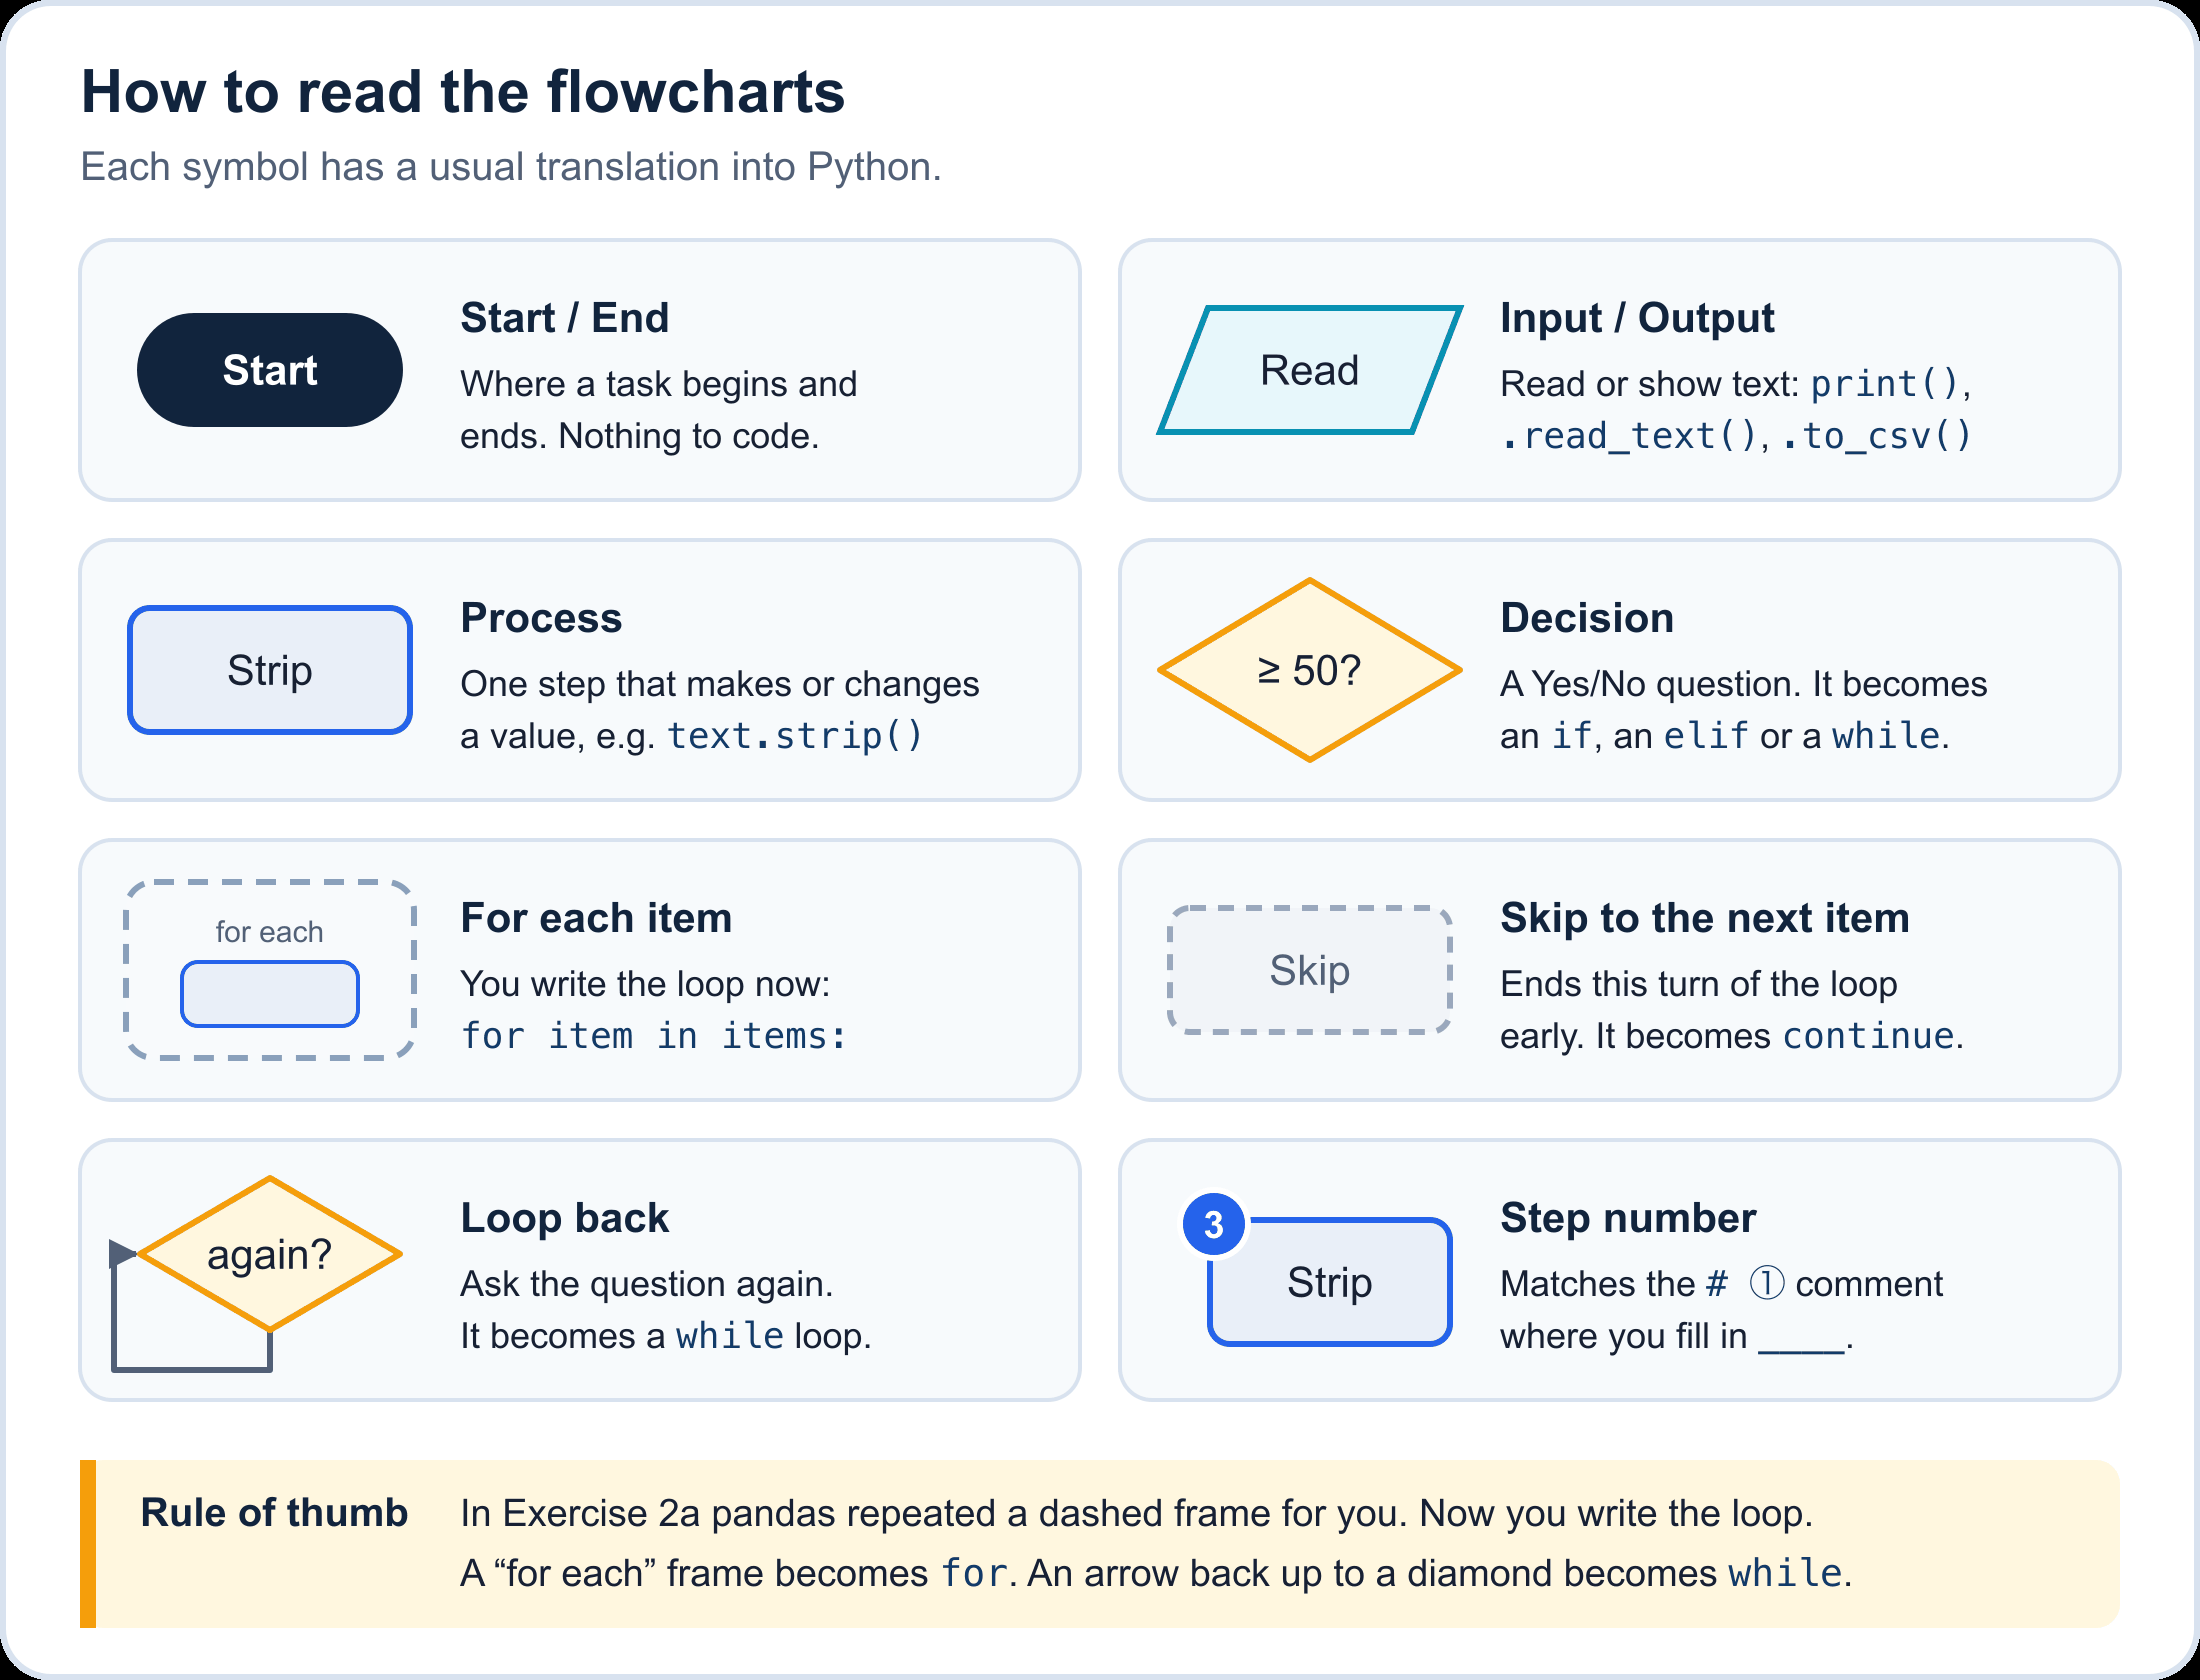

The rule of thumb at the bottom is the key idea of this exercise. Watch for it in Tasks 3, 5, 6 and 8.

## Your toolbox

Every blank uses one of these. They are on the Weeks 8–10 slides, except `.title()` and `.isdigit()`, which are explained where you need them.

| Purpose | Python |
|---|---|
| Files and paths | `Path("name.txt")` · `.write_text(text, encoding="utf-8")` · `.read_text(encoding="utf-8")` · `with path.open(encoding="utf-8") as handle:` |
| Clean text | `.strip()` · `.upper()` · `.lower()` · `.title()` · `.startswith("#")` · `.isdigit()` |
| Split and join | `text.split("\|")` · `"\n".join(pieces)` · `.splitlines()` · `repr(text)` shows hidden spaces |
| Decisions | `if` / `elif` / `else` · `and` · `or` · `not` · `is None` · `return` |
| Loops | `for item in items:` · `enumerate(items, start=1)` · `continue` · `while condition:` · `count += 1` |
| Errors | `try:` … `except ValueError:` around `int(text)` |
| Patterns | `re.fullmatch(pattern, text)` · `re.search(pattern, text)` · `[0-9]{3}` means exactly three digits |
| Tables and files | `pd.DataFrame(list_of_dicts)` · `.to_csv(path, index=False)` · `pd.read_csv(path, dtype={...})` |
| Show results | f-strings: `{value:.1f}` one decimal · `{text:<8}` pad to 8 on the right · `{n:>3}` pad to 3 on the left |

In [ ]:
import re
from pathlib import Path

import pandas as pd

print("pandas", pd.__version__)

---
## Task 1 · Write and read a text file

**Question:** Save the tutor's lines as a real file, then read the file back. What is really in each line?

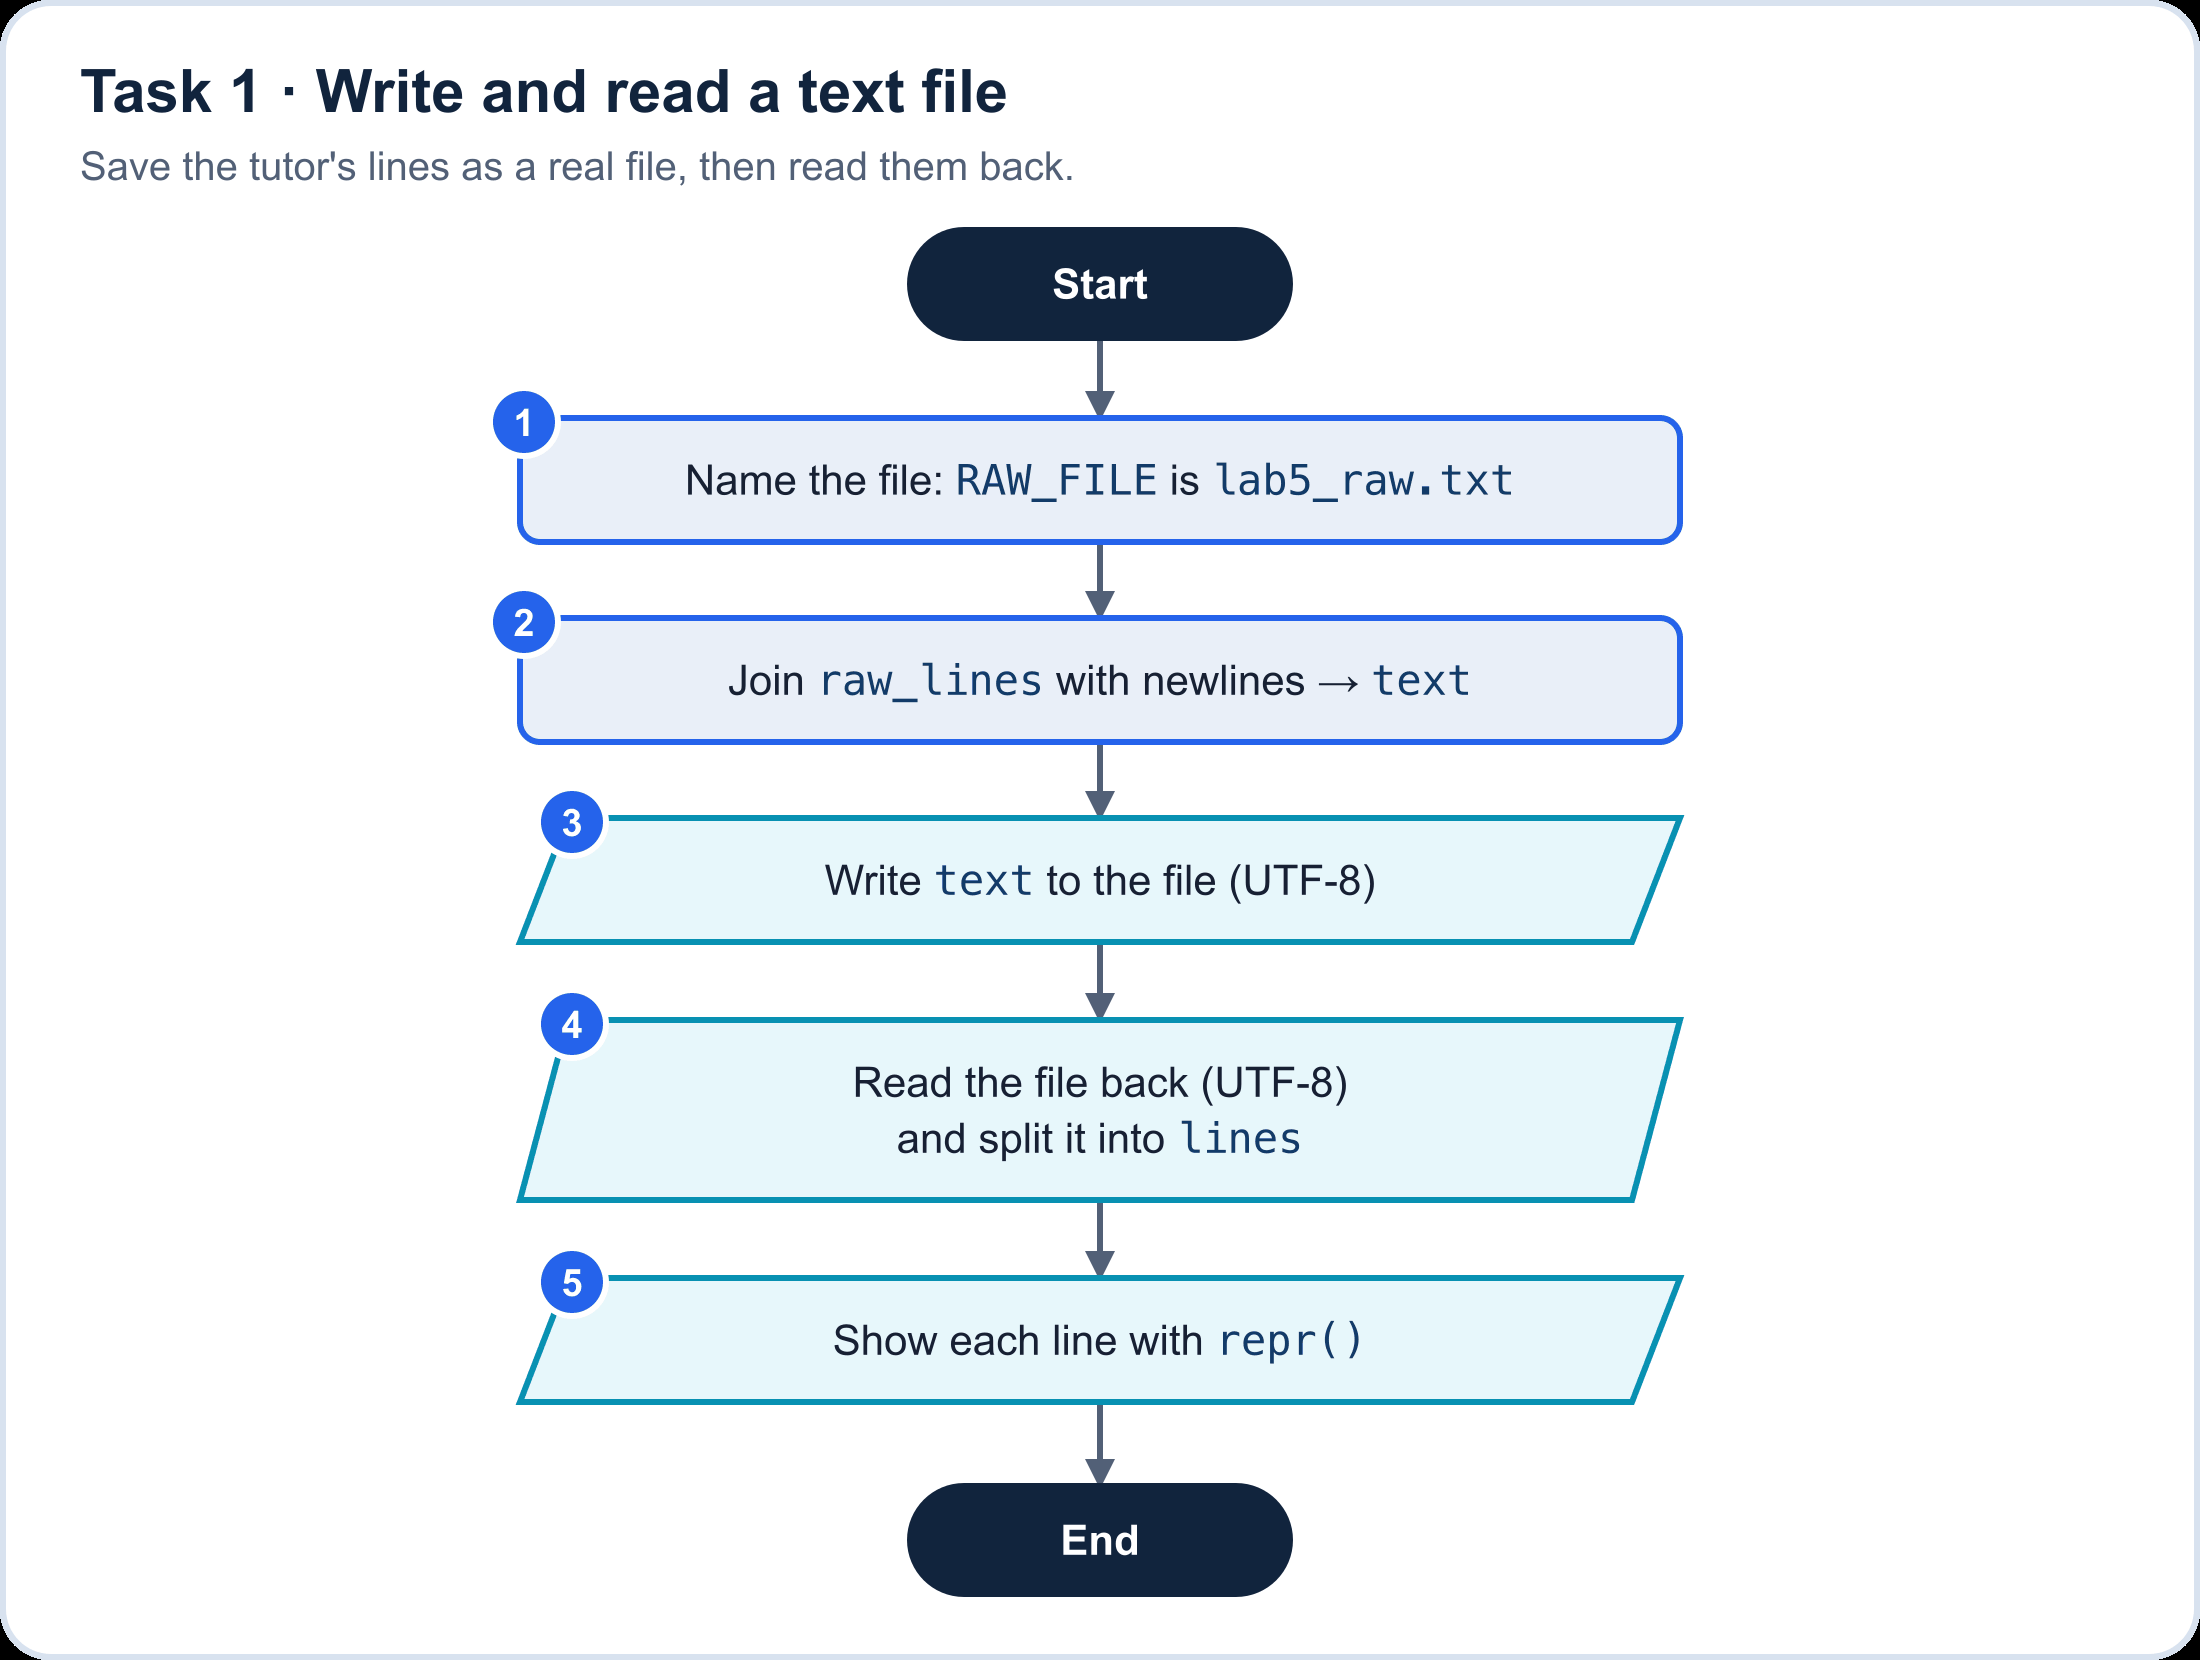

In [ ]:
# The tutor's typing, exactly as it arrived
raw_lines = [
    "# Lab 5 marks typed by the tutor: matric | name | lab mark (out of 30)",
    "S101 | Aina | 24",
    "s102 |  ben | 20",
    "S103|Chong|28",
    "S104 | Devi | ",
    "",
    "S105 | Emir | 16",
    "  S106 | FARAH | 14  ",
    "S1O7 | Gopal | 25",
    "S108 | Hana | 62",
    "S109 | Irfan | Absent",
    "S110 | Jun Wei | 19.5",
    "S111 Mei Ling 27",
]

# ①
RAW_FILE = ____("lab5_raw.txt")

# ② A newline between the lines, and one at the very end
text = ____.____(raw_lines) + "\n"

# ③
RAW_FILE.____(text, encoding="utf-8")

# ④
text_back = RAW_FILE.____(encoding="utf-8")
lines = text_back.____()

# ⑤
print(len(lines), "lines")
for line in lines:
    print(repr(line))

In [ ]:
# Check: run this after the cell above
assert RAW_FILE.exists(), "③ write text to RAW_FILE"
assert text.count("\n") == len(raw_lines) and text.endswith("S111 Mei Ling 27\n"), "② join the lines with a newline, then add one at the end"
assert lines == raw_lines, "④ read the file back and split it into lines"
print("✅ Task 1 done")

**✍️ Think:** Line 8 prints as `'  S106 | FARAH | 14  '`. Why print each line with `repr()` instead of plain `print(line)`?

*Your answer:* 

---
## Task 2 · Clean one line

**Question:** How do you turn one typed line into a tidy matric, name and mark text?

![Task 2 flowchart of the function clean_fields(line): 1 split line at every bar, giving parts; 2 strip the spaces from every piece, giving fields; 3 decision: exactly 3 fields? No return None; Yes 4 put matric in upper case and name in title case; return matric, name and mark_text.](attachment:task2.png)

`.title()` capitalises the first letter of every word: `"jun wei".title()` gives `"Jun Wei"`.
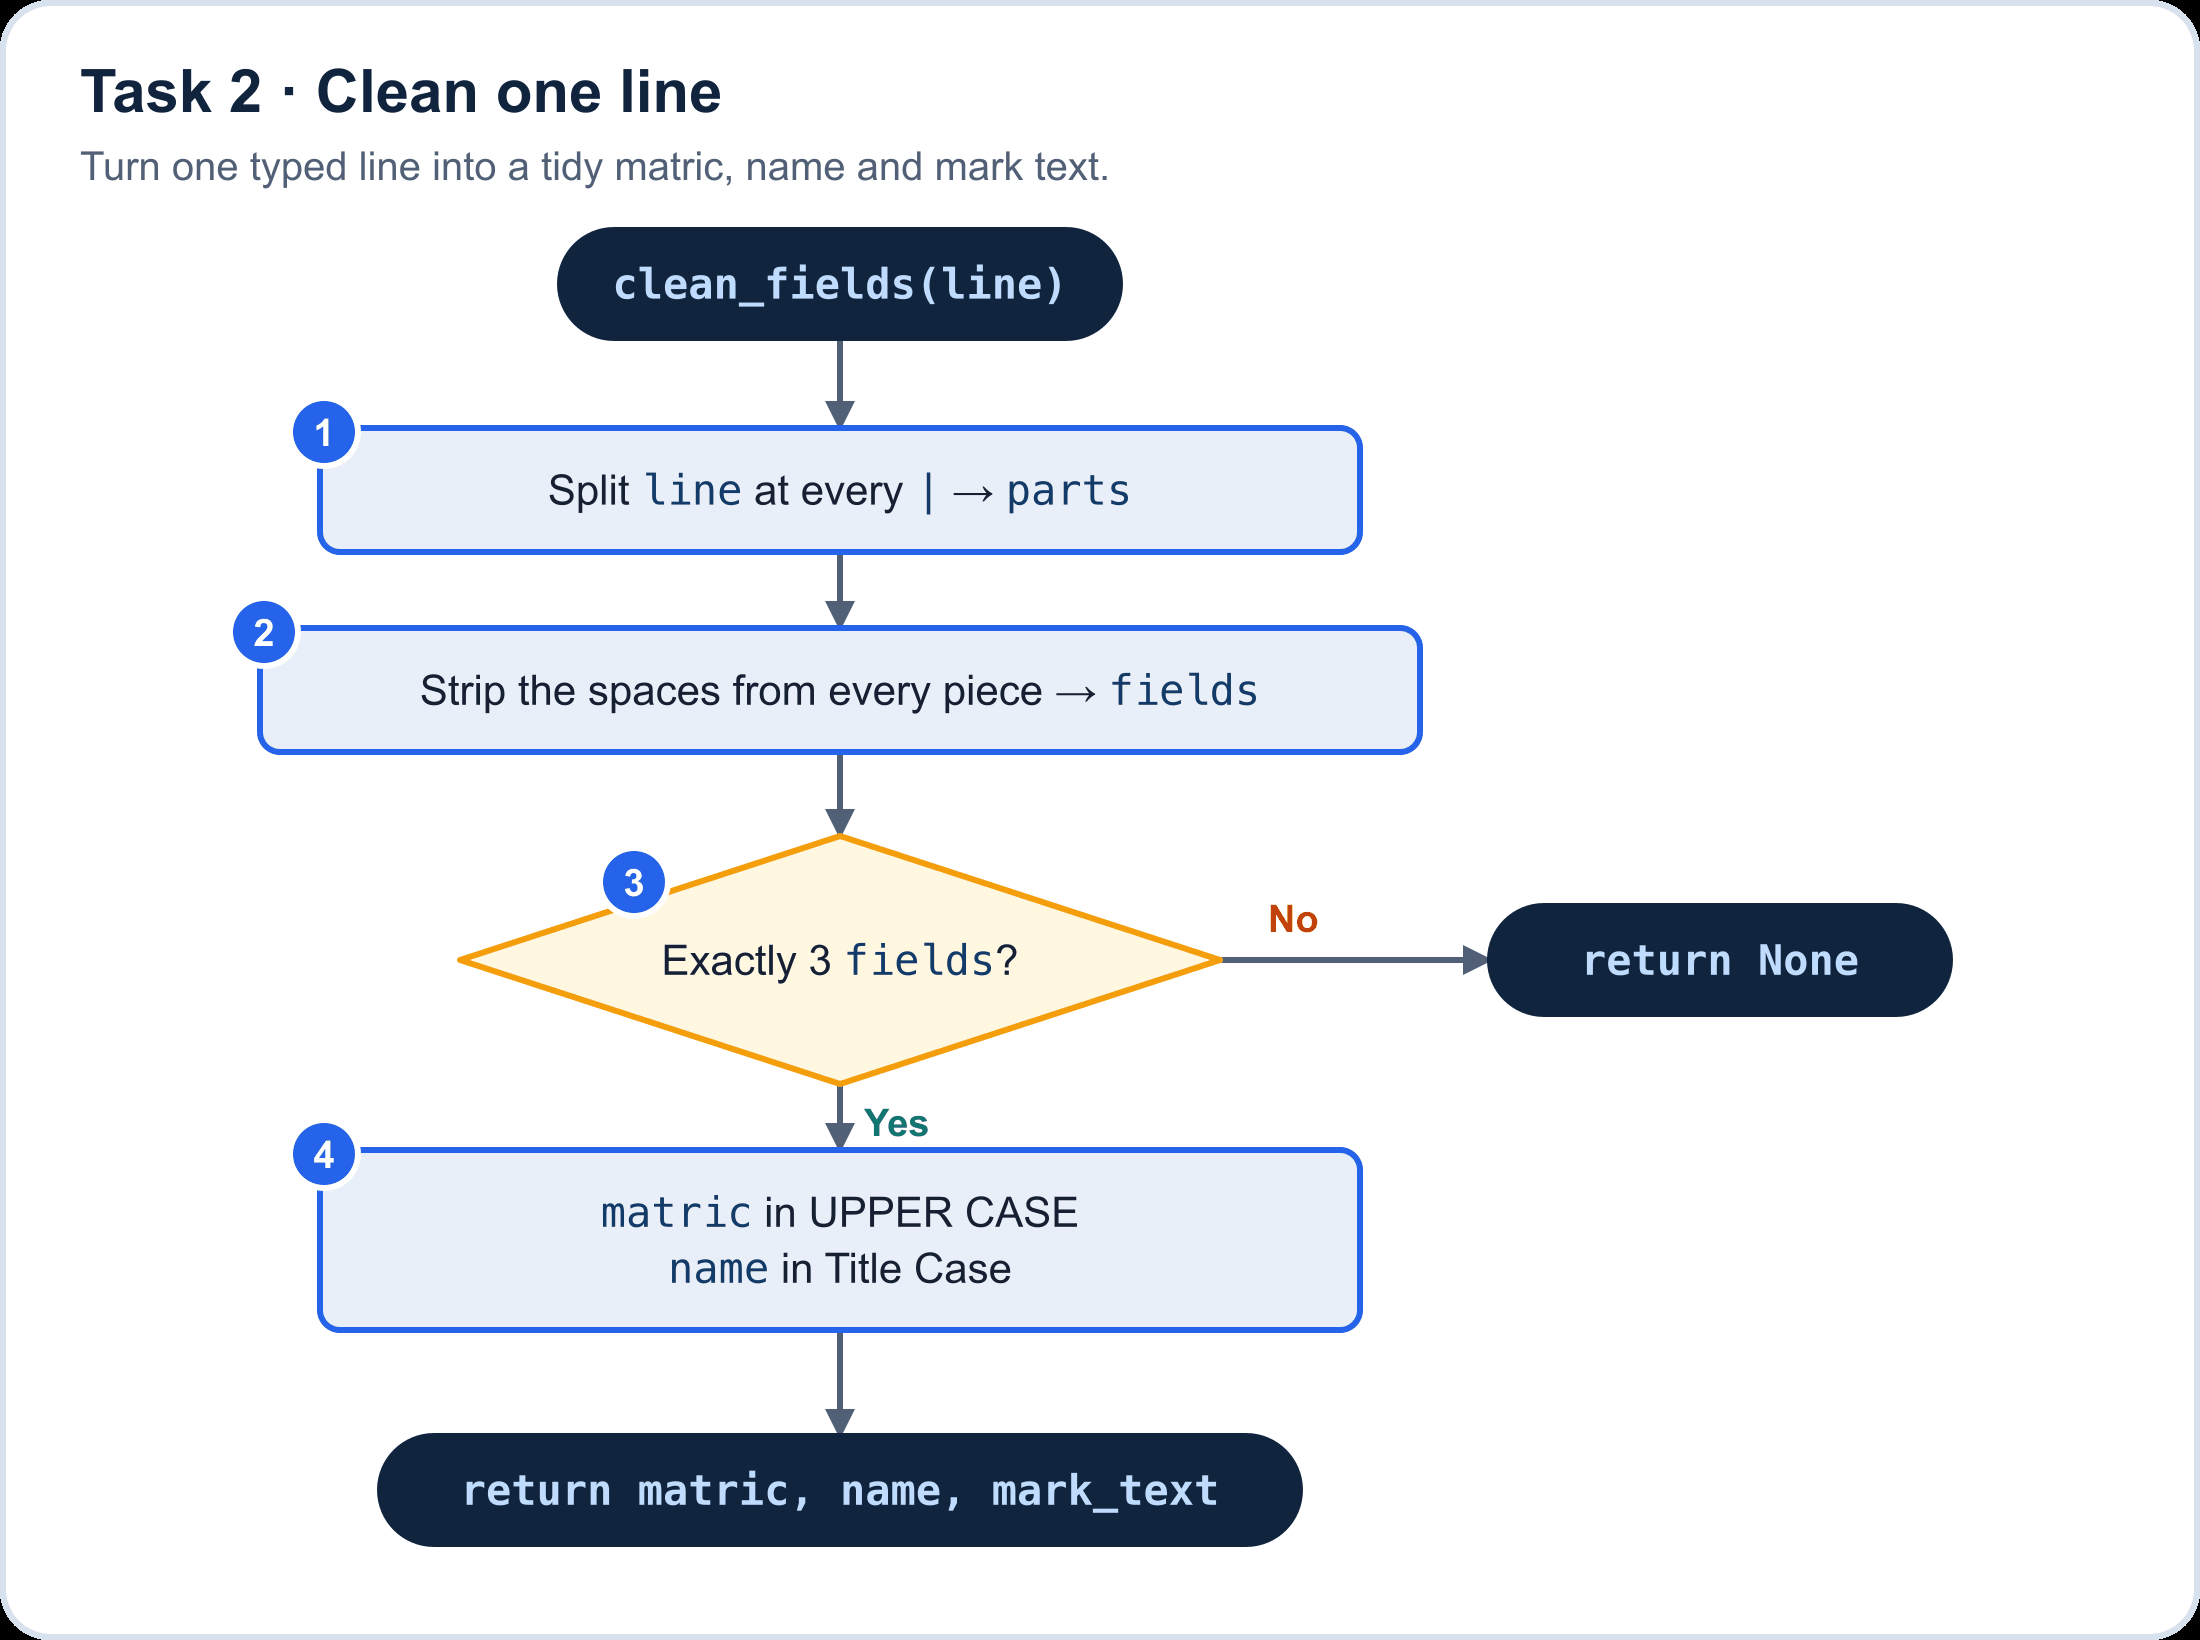

In [ ]:
# A function, so that Task 5 can reuse it on every line
def clean_fields(line):
    parts = line.____("|")                    # ①
    fields = [part.____() for part in parts]  # ②
    if len(fields) ____ 3:                    # ③
        return ____
    matric = fields[0].____()                 # ④
    name = fields[1].____()
    mark_text = fields[2]
    return matric, name, mark_text

# Try it on two lines from Task 1
print(clean_fields(lines[2]))
print(clean_fields(lines[12]))

In [ ]:
# Check: run this after the cell above
assert clean_fields("s102 |  ben | 20") == ("S102", "Ben", "20"), "① ② ④ split at |, strip every piece, then fix the case"
assert clean_fields("  S106 | FARAH | 14  ") == ("S106", "Farah", "14"), "④ the name should be in Title Case"
assert clean_fields("S104 | Devi | ") == ("S104", "Devi", ""), "② an empty mark stays an empty string"
assert clean_fields("S111 Mei Ling 27") is None, "③ a line without exactly 3 pieces gives None"
print("✅ Task 2 done")

**✍️ Think:** Why strip every piece after splitting, instead of stripping the whole line once?

*Your answer:* 

---
## Task 3 · Check a matric number with a pattern

**Question:** A matric is `S` followed by exactly three digits. Which test proves that a code follows the rule?

![Task 3 flowchart: Start; 1 pattern is S, then exactly 3 digits 0 to 9; inside a frame for each code, 2 found: is a matching piece anywhere? 3 whole: does the whole code match? 4 show code, found and whole; after the frame, 5 keep the stricter test as valid_matric(matric); End.](attachment:task3.png)
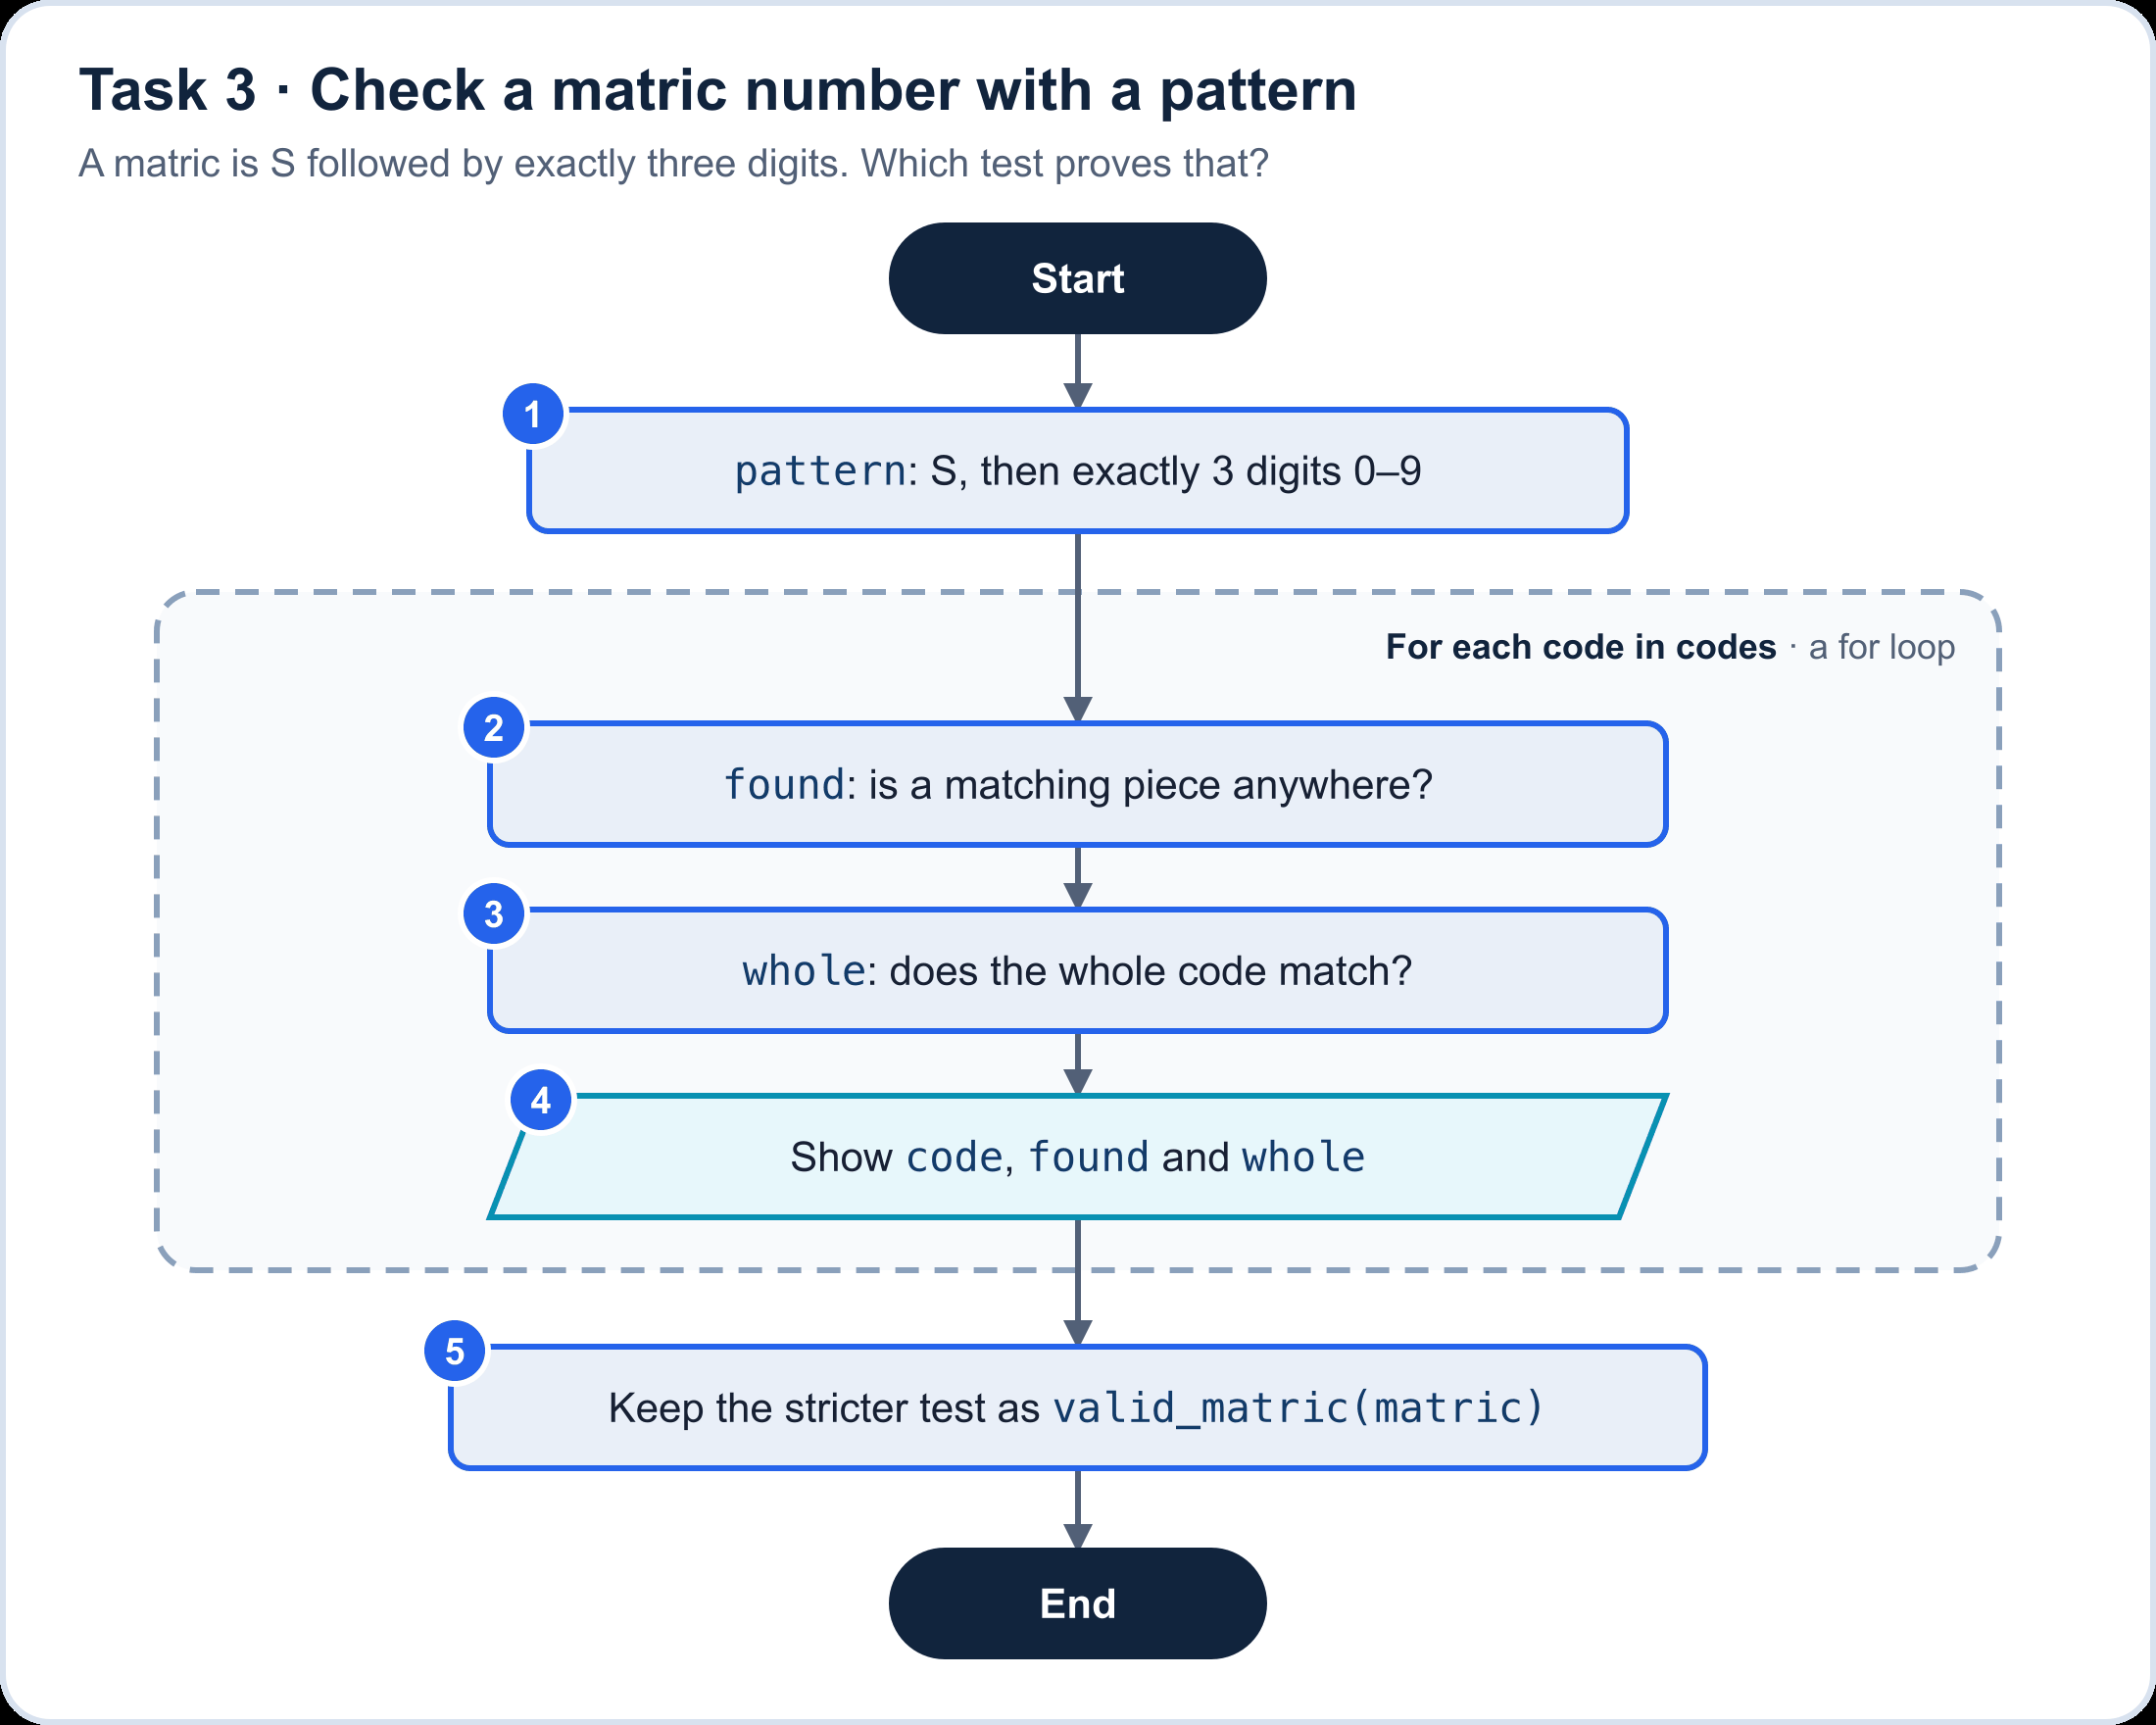

In [ ]:
# ① Write the whole pattern as a raw string: r"..."
pattern = ____

codes = ["S101", "S1O7", "S1011", "XS101", "s101"]

# ② – ④ The frame says "for each code", so write a for loop
____ code in codes:
    found = re.____(pattern, code) is not None        # ②
    whole = re.____(pattern, code) is not None        # ③
    print(f"{code:<6} found={found}  whole={whole}")  # ④

# ⑤ Keep the stricter test as a function for Task 5
def valid_matric(matric):
    return re.fullmatch(pattern, matric) is not None

In [ ]:
# Check: run this after the cell above
assert valid_matric("S101") and valid_matric("S999"), "① S followed by three digits is valid"
assert not valid_matric("S1O7"), "① O (the letter) is not 0 (the digit)"
assert not valid_matric("S1011") and not valid_matric("XS101"), "① the pattern is S, then exactly 3 digits"
assert not valid_matric("s101"), "① the S must be upper case"
assert [re.search(pattern, c) is not None for c in codes] == [True, False, True, True, False], "② search looks for a matching piece anywhere"
print("✅ Task 3 done")

**✍️ Think:** `re.search` says `True` for `S1011` and `XS101`. Why is it the wrong test for checking a matric?

*Your answer:* 

---
## Task 4 · Check a mark with if / elif / else

**Question:** Is the typed mark usable? If not, what exactly is wrong with it?

![Task 4 flowchart of the function mark_problem(mark_text): 1 is it empty? Yes return missing; 2 is it absent in lower case? Yes return absent; 3 only digits 0 to 9? No return not a whole number; 4 is the int value above 30? Yes return above 30; otherwise return ok. The first Yes wins.](attachment:task4.png)

`.isdigit()` is `True` when every character is a digit: `"24".isdigit()` is `True`, but `"19.5".isdigit()` and `"-3".isdigit()` are `False`.
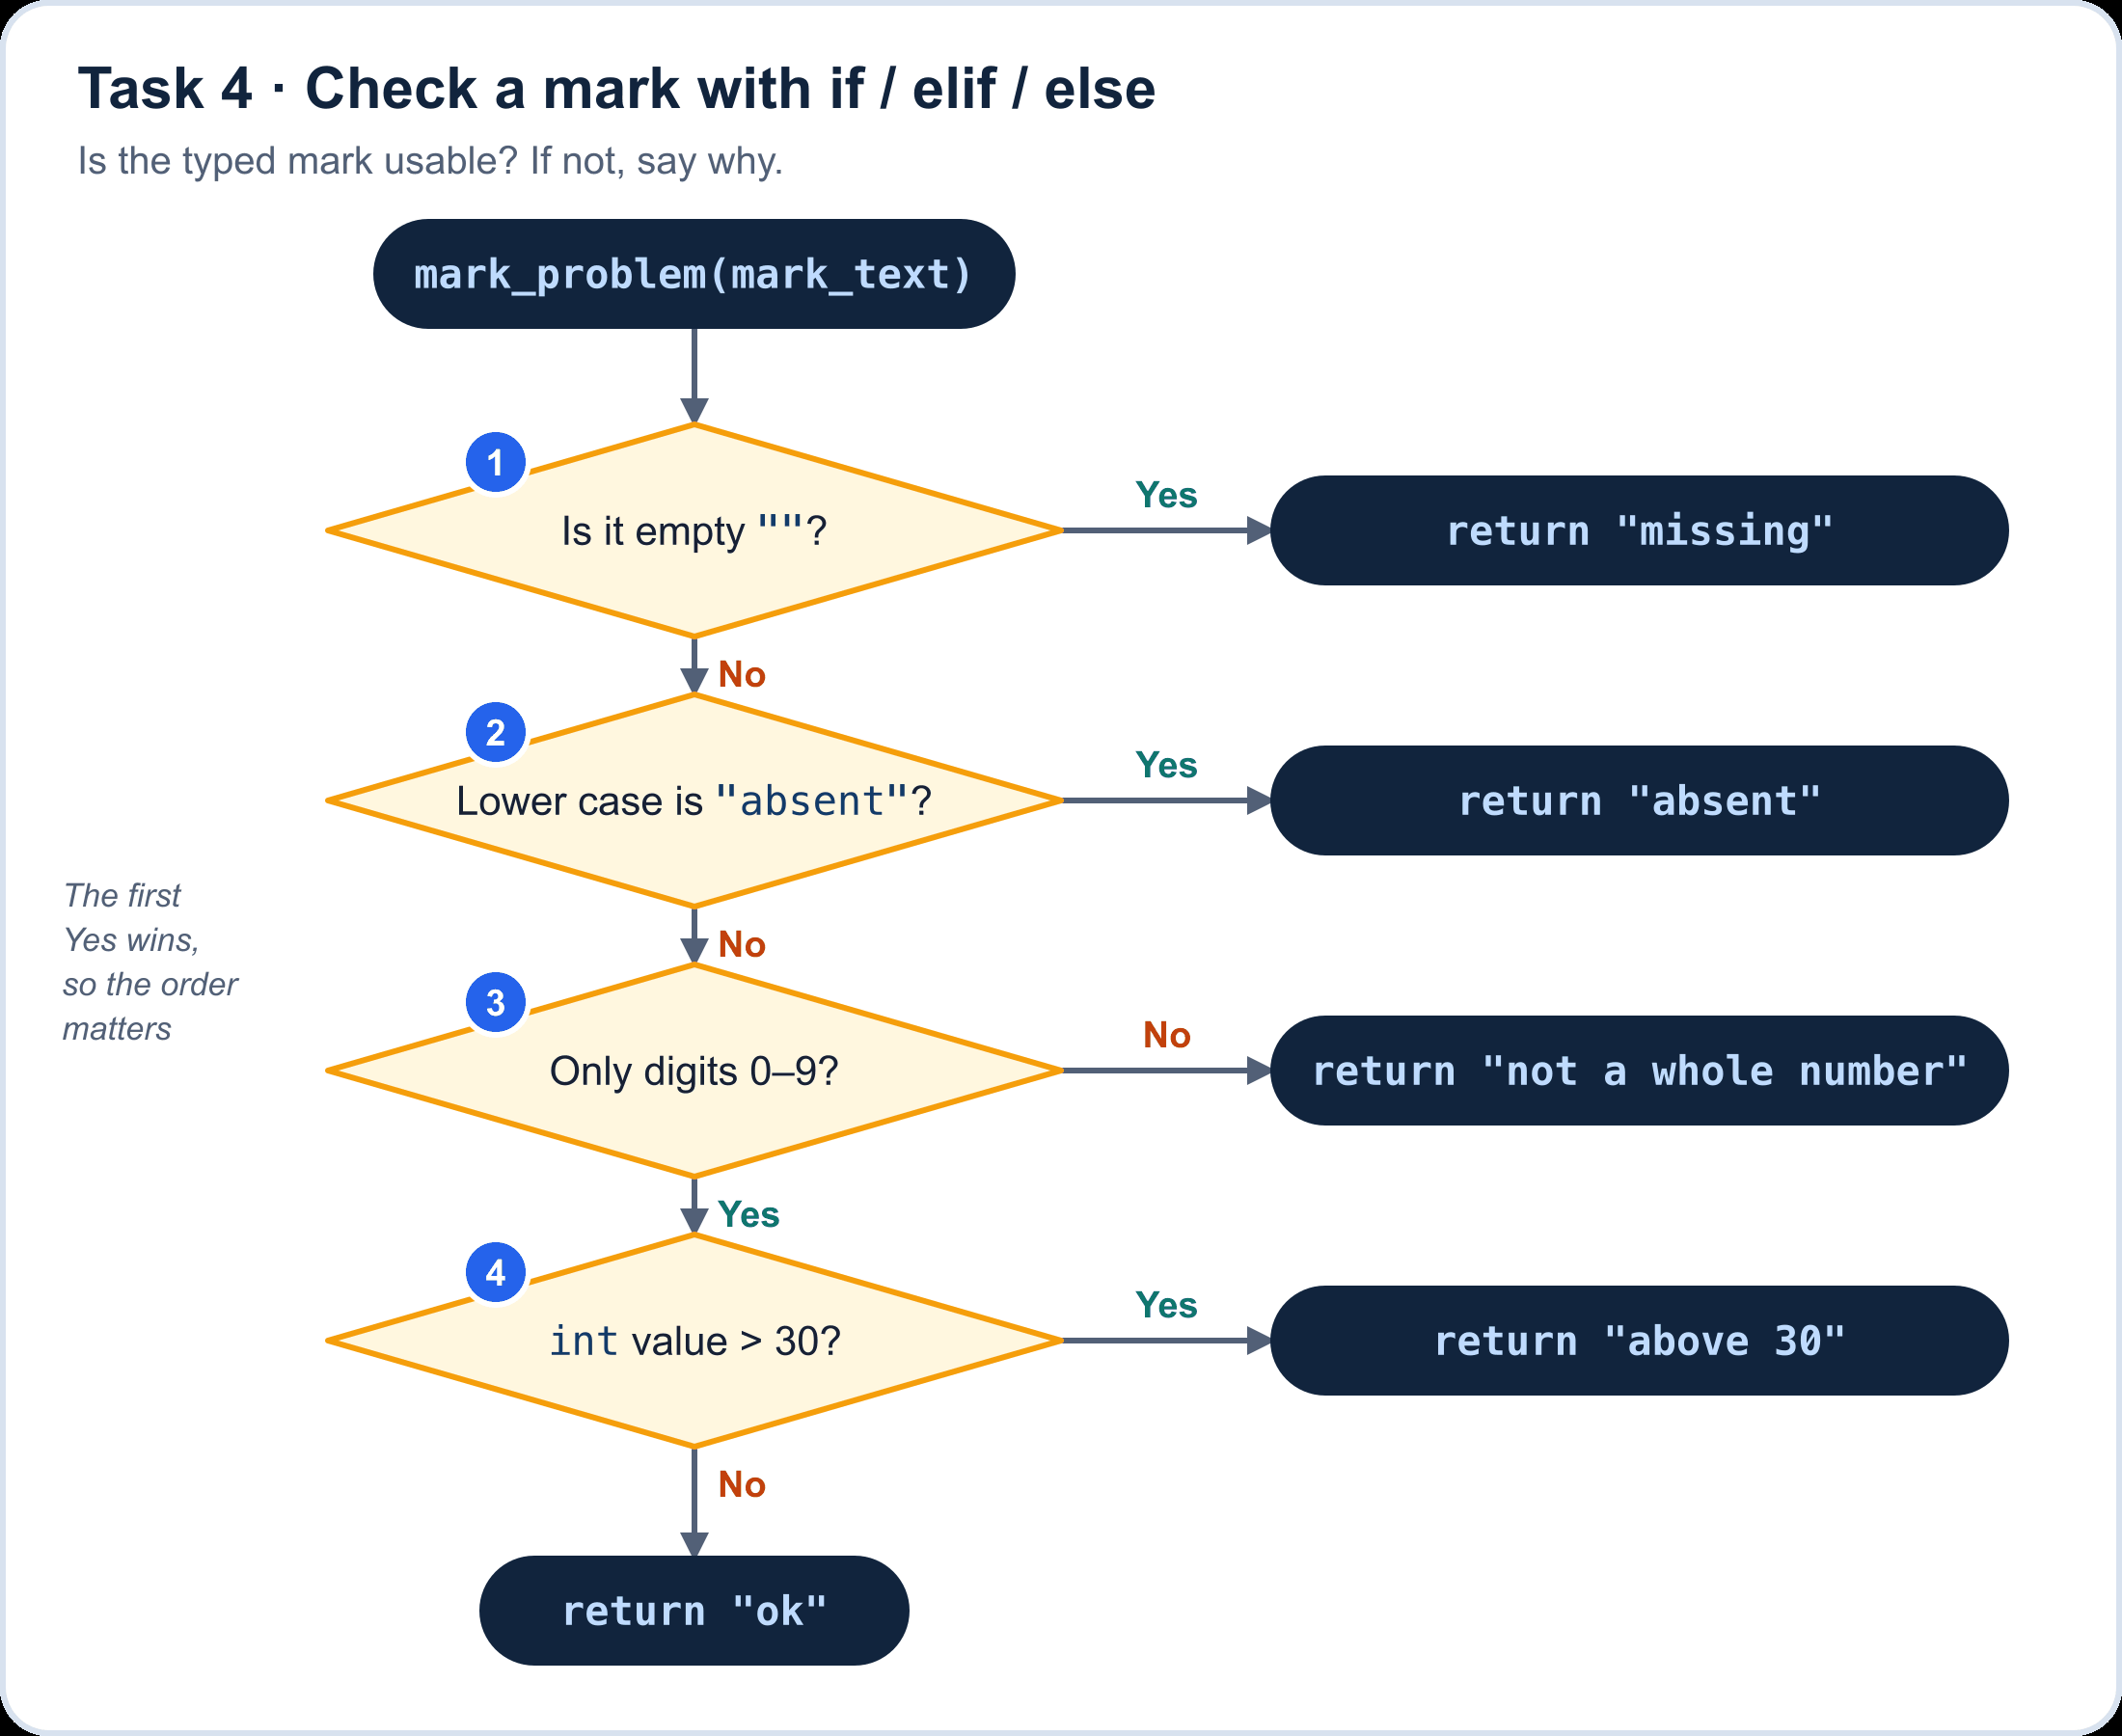

In [ ]:
# ① – ④ A chain of decisions becomes if / elif / else. The first True branch wins.
def mark_problem(mark_text):
    if mark_text == ____:               # ①
        return "missing"
    elif mark_text.____() == "absent":  # ②
        return "absent"
    elif ____ mark_text.isdigit():      # ③
        return "not a whole number"
    elif ____(mark_text) > ____:        # ④
        return "above 30"
    ____:
        return "ok"

# Try every kind of mark text
for mark_text in ["24", "", "Absent", "19.5", "62", "30", "0"]:
    print(repr(mark_text), "→", mark_problem(mark_text))

In [ ]:
# Check: run this after the cell above
assert mark_problem("24") == "ok" and mark_problem("0") == "ok", "an ordinary mark is ok"
assert mark_problem("30") == "ok" and mark_problem("31") == "above 30", "④ 30 itself is allowed; 31 is not"
assert mark_problem("") == "missing", "① an empty string means missing"
assert mark_problem("ABSENT") == "absent", "② compare in lower case, so Absent and ABSENT both match"
assert mark_problem("19.5") == "not a whole number" and mark_problem("-3") == "not a whole number", "③ only digits make a whole number"
print("✅ Task 4 done")

**✍️ Think:** Why must *Only digits?* (③) come before *Above 30?* (④)? What happens to `"19.5"` if you swap them?

*Your answer:* 

---
## Task 5 · Loop over every line of the file

**Question:** Which lines can be accepted? For every other line, record its line number and the reason.

![Task 5 flowchart: Start; 1 empty lists accepted and problems, n_skipped is 0; inside a frame for each line of the file, 2 read the next line, giving line_number and the stripped line; 3 blank or starts with a hash? Yes skip it and add 1 to n_skipped; 4 clean_fields gives 3 fields? 5 valid_matric? 6 mark_problem says ok? A No at 4, 5 or 6 records the problem, then goes to the next line; 7 add matric, name and int lab to accepted; after the frame, 8 show the counts and every problem; End.](attachment:task5.png)

This task uses your three functions from Tasks 2–4. Each problem is stored as a dictionary, so Task 7 can save the problems as a table.
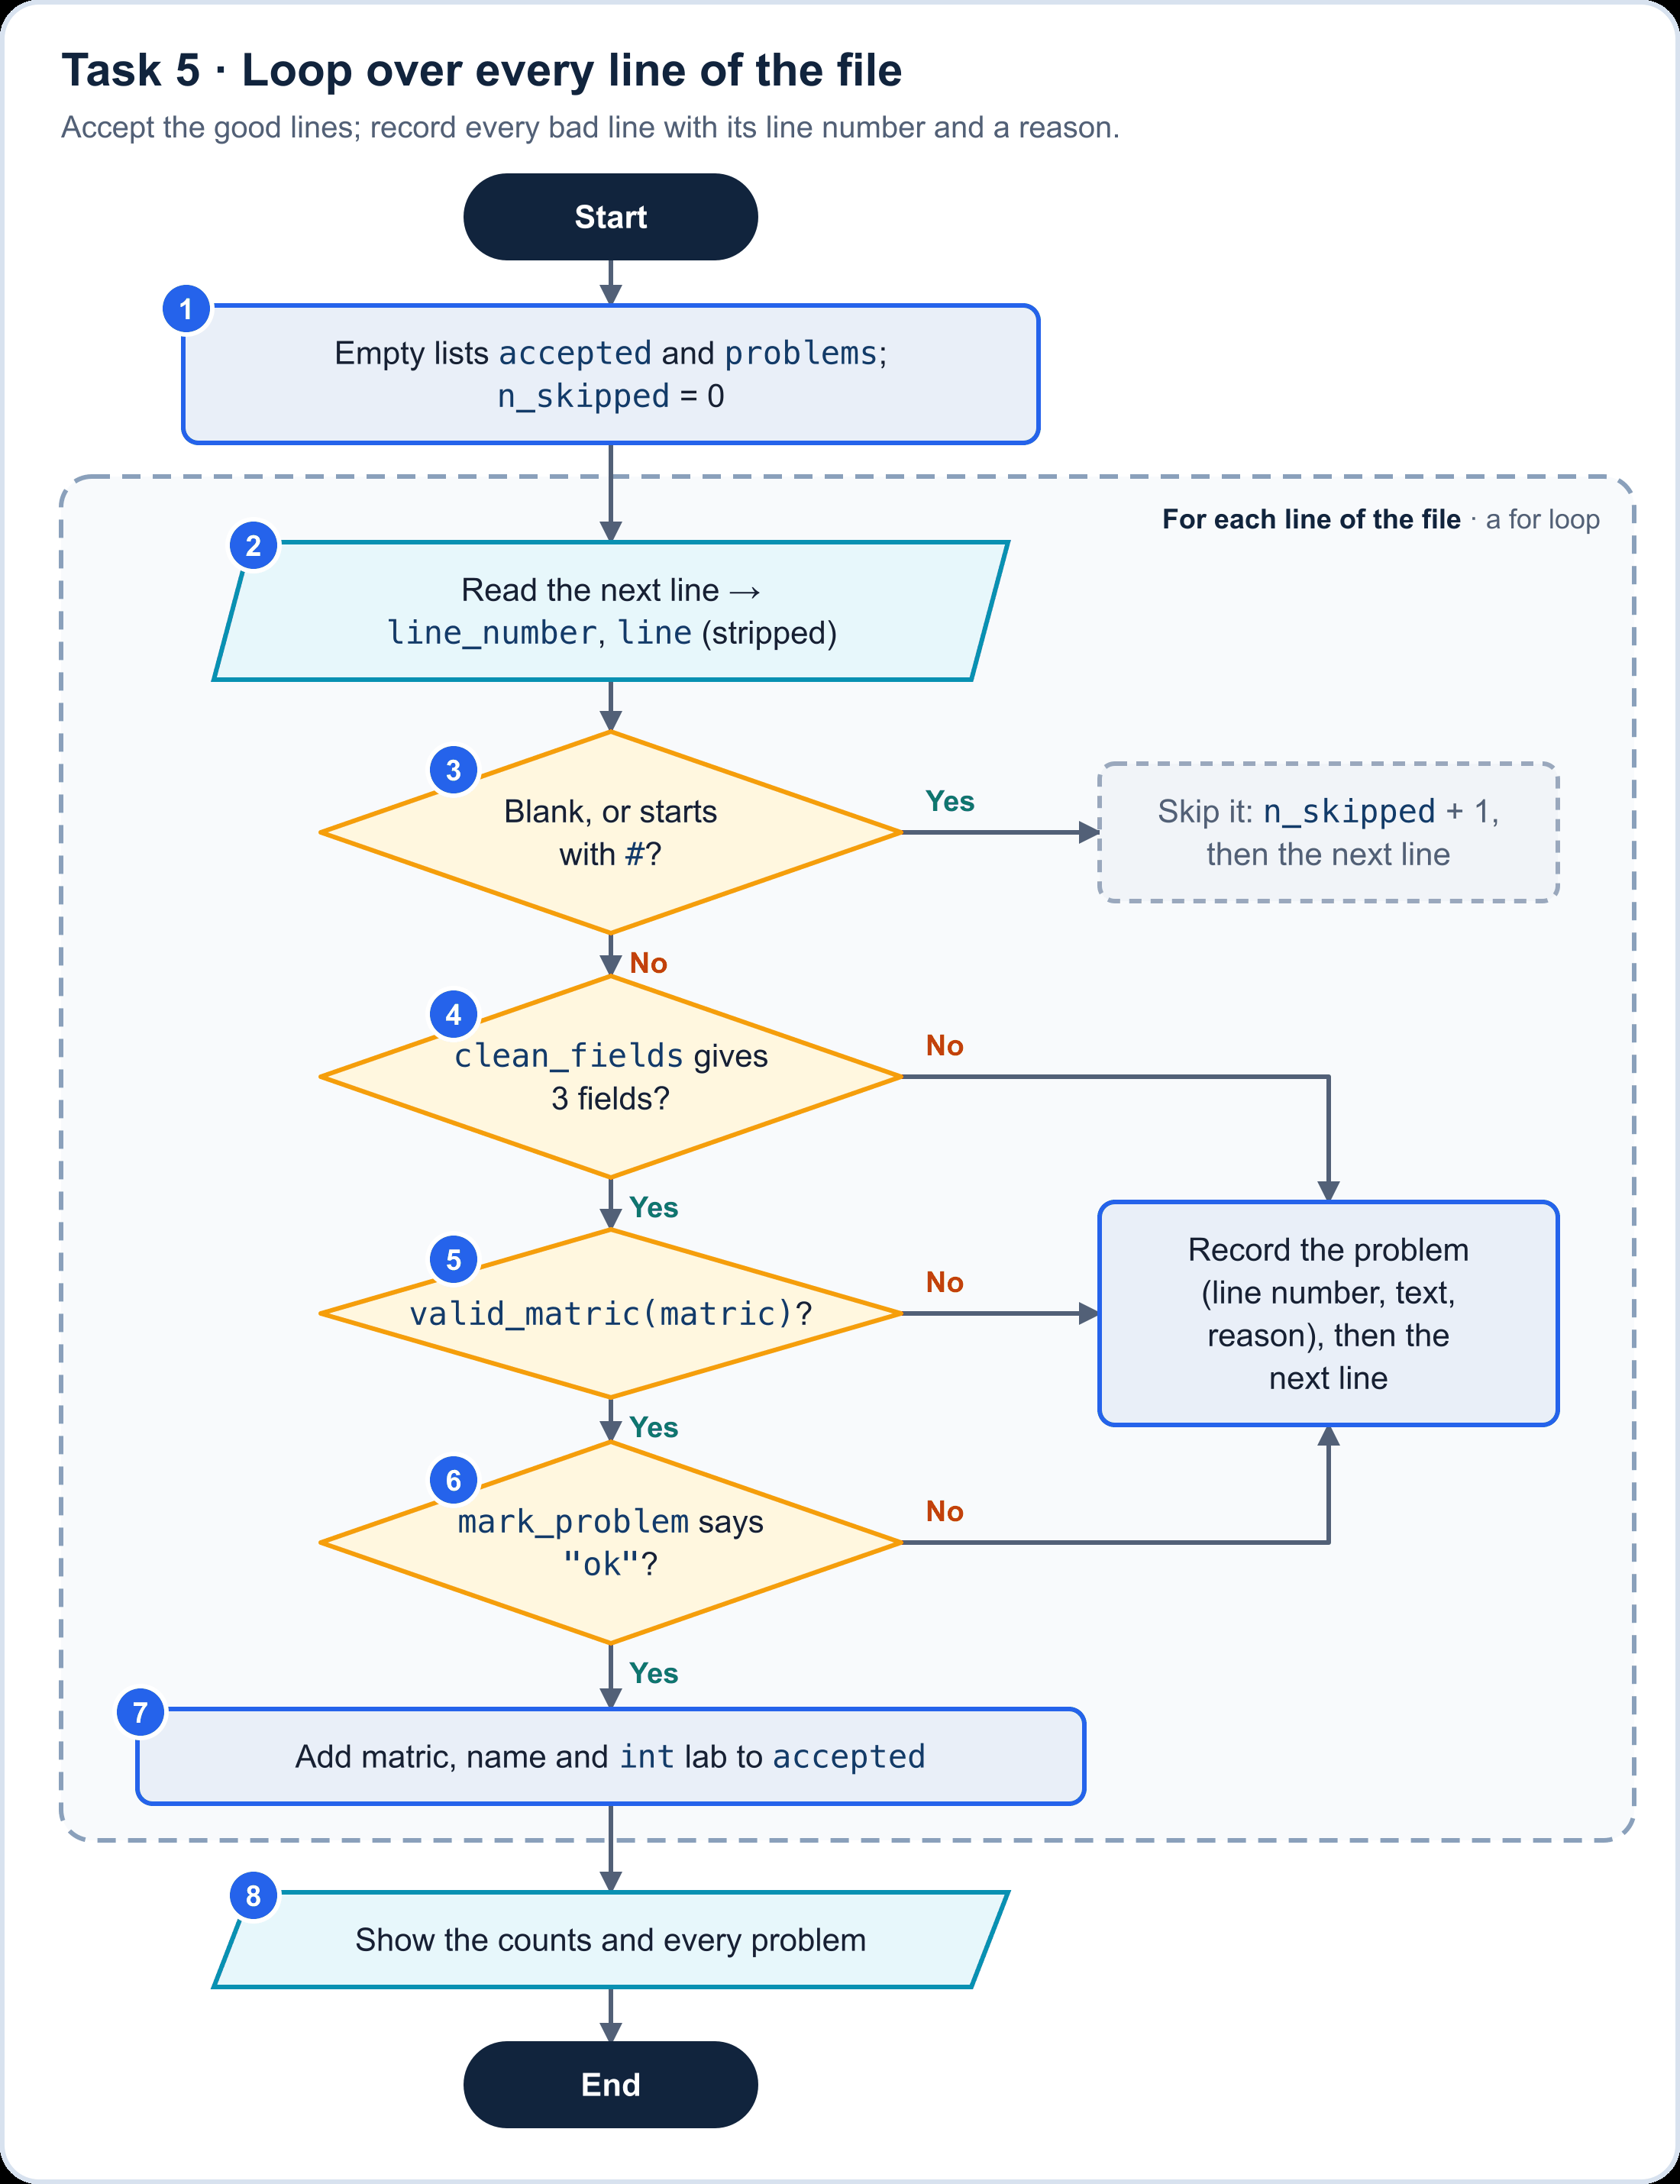

In [ ]:
# ① Start the collections before the loop
accepted = []
problems = []
n_skipped = 0

# ② Open the file and number its lines from 1
with RAW_FILE.____(encoding="utf-8") as handle:
    for line_number, line in ____(handle, start=1):
        line = line.strip()

        # ③ Skip blank lines and comments
        if line == "" ____ line.startswith("#"):
            n_skipped += 1
            ____

        # ④
        fields = clean_fields(line)
        if fields ____:
            problems.append({"line": line_number, "text": line, "reason": "expected 3 fields"})
            continue
        matric, name, mark_text = fields

        # ⑤
        if not valid_matric(matric):
            problems.append({"line": line_number, "text": line, "reason": "matric is not S + 3 digits"})
            continue

        # ⑥ ⑦
        reason = mark_problem(mark_text)
        if reason == "ok":
            accepted.____({"matric": matric, "name": name, "lab": ____(mark_text)})
        else:
            problems.append({"line": line_number, "text": line, "reason": reason})

# ⑧
print(f"{len(accepted)} accepted, {len(problems)} problems, {n_skipped} skipped")
for problem in problems:
    print(f"line {problem['line']:>2}: {problem['reason']:<27} {problem['text']!r}")

In [ ]:
# Check: run this after the cell above
assert n_skipped == 2, "③ skip the comment line and the blank line, and count them"
assert [student["matric"] for student in accepted] == ["S101", "S102", "S103", "S105", "S106"], "④ – ⑦ expected 5 accepted students"
assert all(type(student["lab"]) is int for student in accepted), "⑦ store the lab mark as a whole number, not text"
assert [problem["line"] for problem in problems] == [5, 9, 10, 11, 12, 13], "② ⑥ record a problem for every rejected line, numbered from 1"
print("✅ Task 5 done")

**✍️ Think:** Line 9 (`S1O7`) is rejected only for its matric. If its mark were also `62`, how many reasons would `problems` show for that line, and why? When would you want every reason?

*Your answer:* 

---
## Task 6 · Ask until the answer is valid

**Question:** Devi's mark was left blank. Ask the tutor for it, but give up after 3 tries.

![Task 6 flowchart: Start; 1 mark is None, attempts is 0; 2 decision: no mark yet and attempts fewer than 3? Yes 3 add 1 to attempts and ask the tutor, giving raw; 4 does raw convert to a whole number? No say digits only and loop back to 2; 5 is the value from 0 to 30? No say 0 to 30 only and loop back; Yes mark is the value and loop back; when 2 says No, 6 still no mark? Yes stop and ask the lecturer; No 7 add the record to complete and drop it from the problems; End.](attachment:task6.png)

In a script you would call `input()`, which waits for the keyboard. Here `ask()` stands in for `input()`: it hands back the tutor's answers one at a time, so the notebook runs without waiting. To try your own answers, replace `ask(` with `input(`.
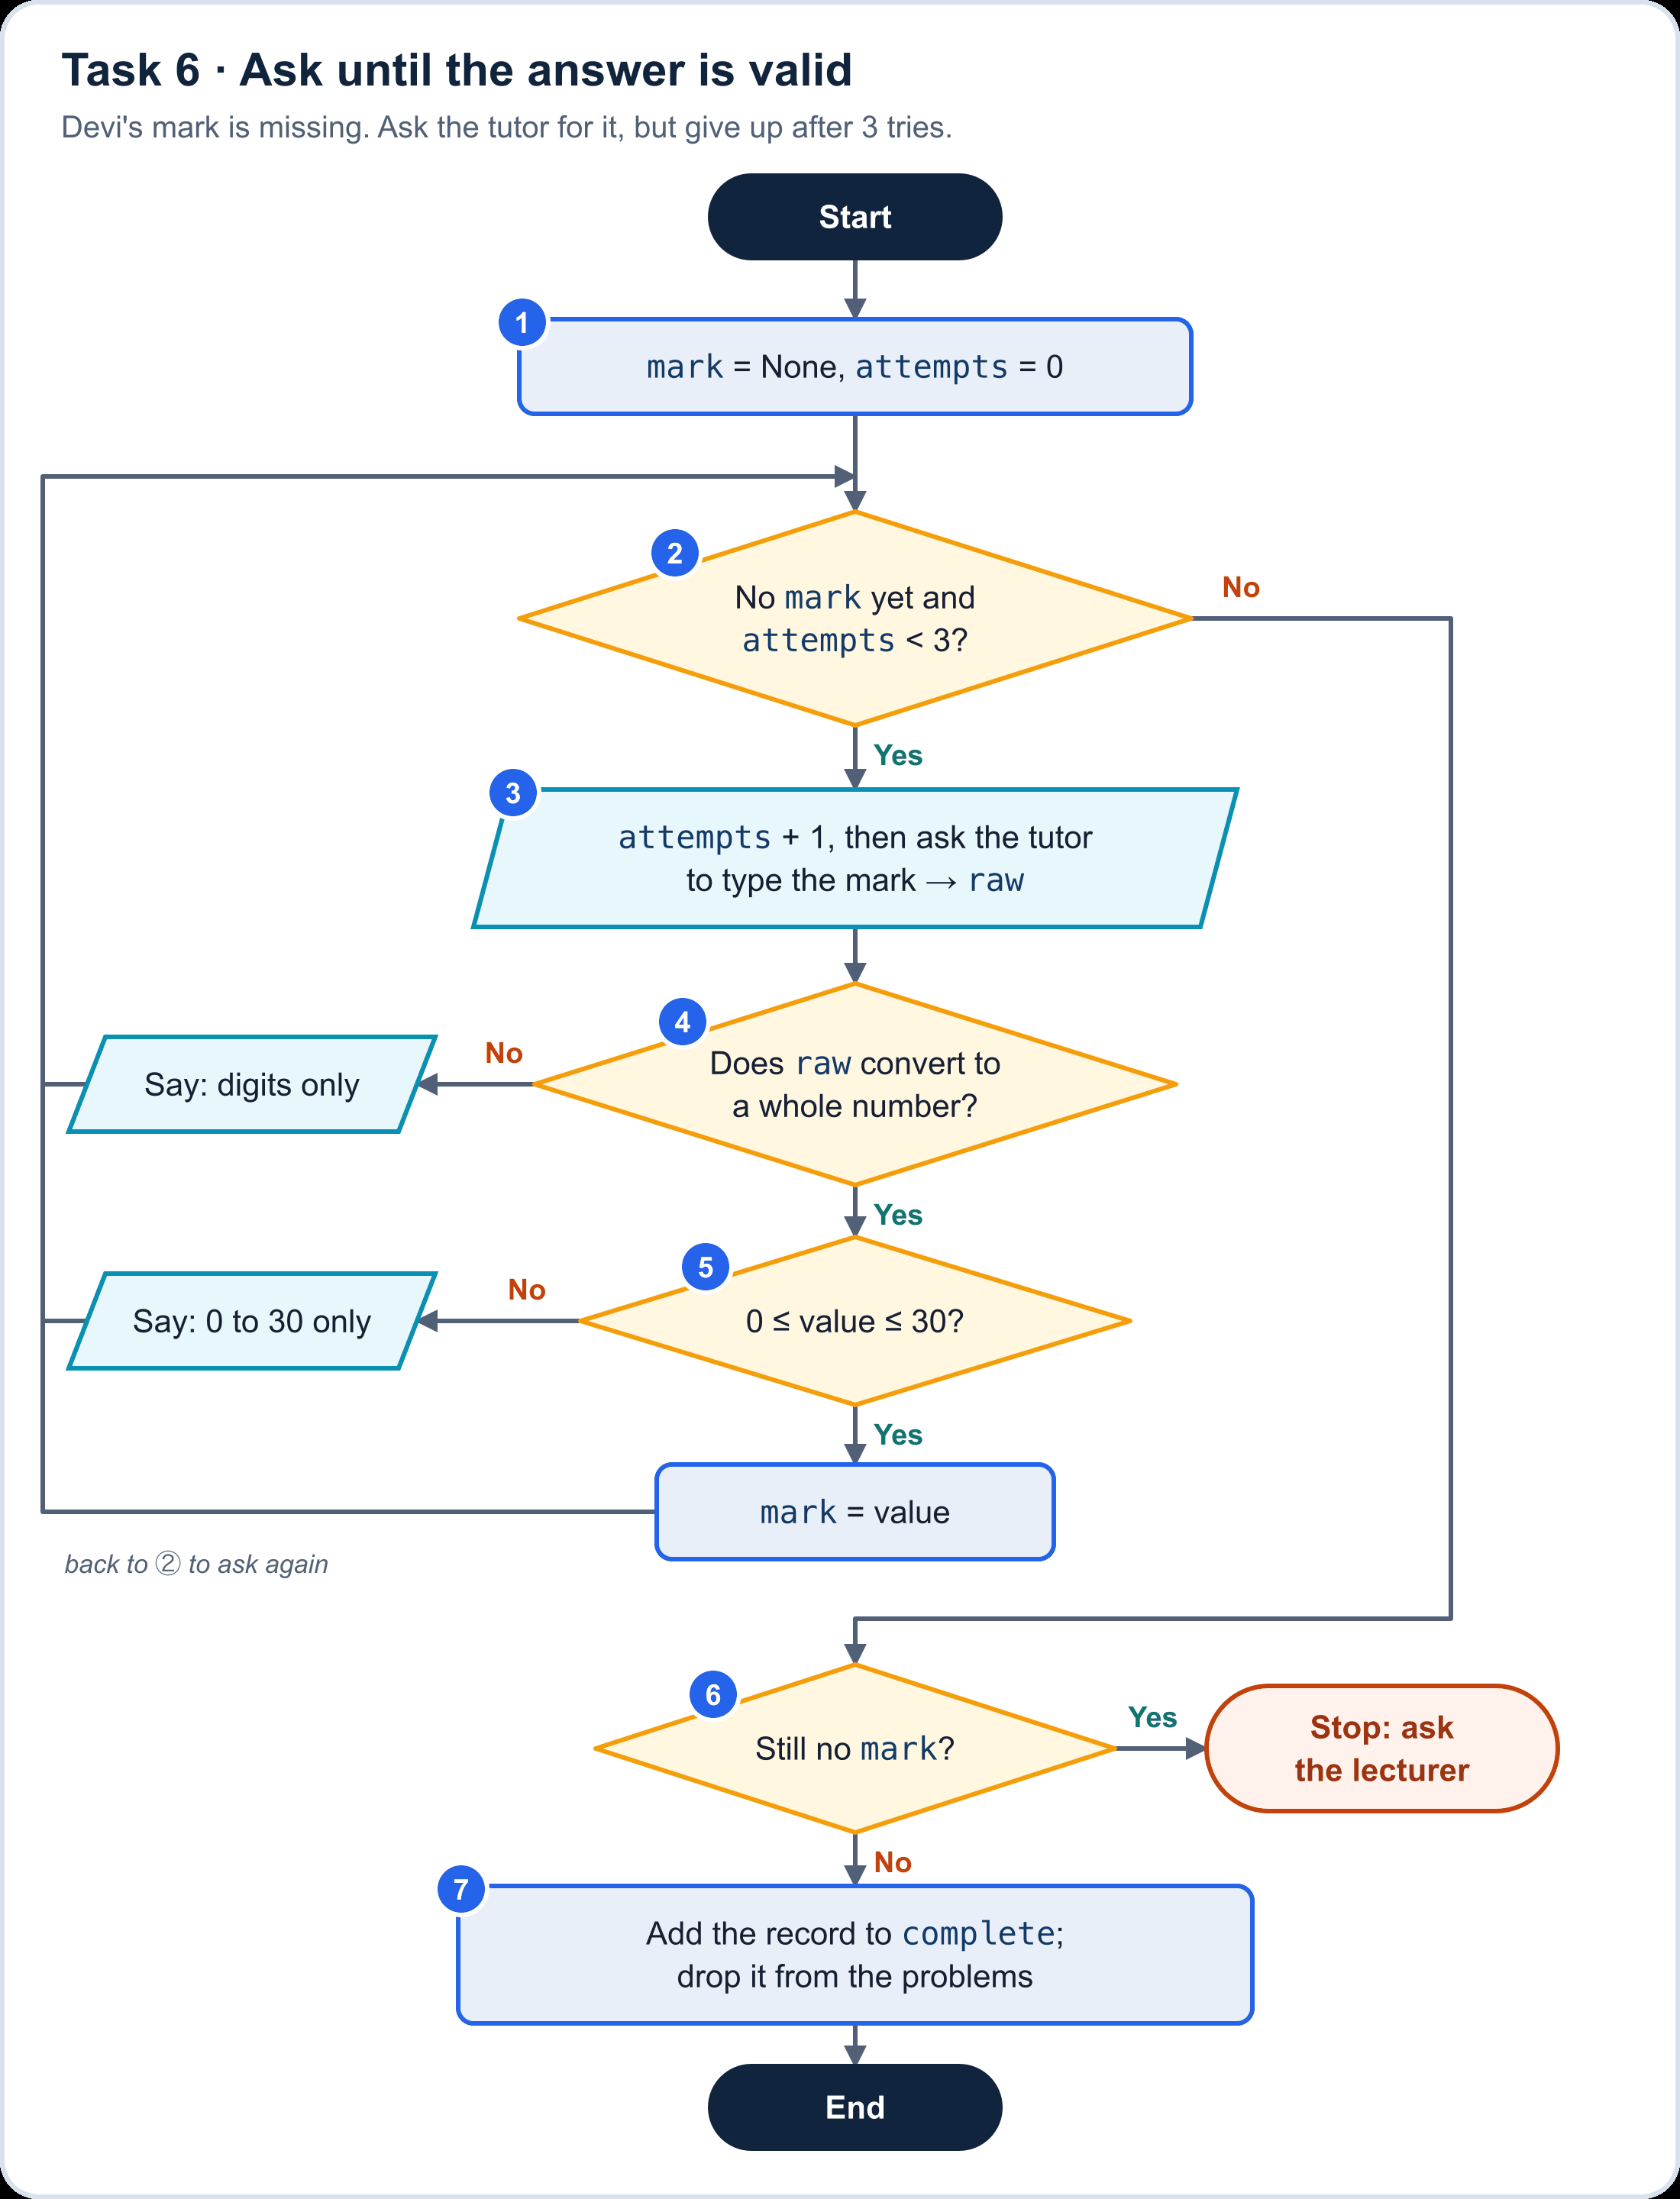

In [ ]:
# The tutor's answers, in the order they type them
tutor_answers = ["twenty-two", "220", " 22 "]

def ask(prompt):
    answer = tutor_answers.pop(0)
    print(prompt + answer)
    return answer

# Which record has the missing mark? (_ holds the empty mark text, which we do not need)
missing = [problem for problem in problems if problem["reason"] == "missing"][0]
matric, name, _ = clean_fields(missing["text"])

# ①
mark = None
attempts = 0

# ② Ask again while there is no mark and fewer than 3 tries
while mark ____ ____ attempts < 3:
    attempts ____ 1                # ③
    raw = ask(f"Lab mark for {name} (try {attempts} of 3): ")
    try:
        value = ____(raw.strip())  # ④
    except ____:
        print("  Please type digits only")
        continue
    if 0 <= value ____ 30:         # ⑤
        mark = value
    else:
        print("  The mark must be from 0 to 30")

# ⑥
if mark is None:
    raise ValueError(f"No valid mark for {name} after 3 tries: ask the lecturer")

# ⑦ New lists, so running this cell twice does not add Devi twice
complete = accepted + [{"matric": matric, "name": name, "lab": mark}]
still_to_check = [problem for problem in problems if problem["reason"] != "missing"]
print(f"{name}: {mark}. {len(complete)} students complete, {len(still_to_check)} lines still to check")

In [ ]:
# Check: run this after the cell above
assert mark == 22 and attempts == 3, "④ ⑤ the first two answers are rejected, and ' 22 ' is accepted on try 3"
assert complete[-1] == {"matric": "S104", "name": "Devi", "lab": 22}, "⑦ add Devi to complete"
assert len(complete) == 6 and [problem["line"] for problem in still_to_check] == [9, 10, 11, 12, 13], "⑦ only the missing-mark problem is solved"
print("✅ Task 6 done")

**✍️ Think:** Suppose the tutor's third answer were wrong too. What would happen? And what would happen if the loop were only `while mark is None:`?

*Your answer:* 

---
## Task 7 · Save the clean data and read it back

**Question:** Save the clean marks and the lines still to check as CSV files. Is the saved file really what you meant to save?

![Task 7 flowchart: Start; 1 make the folder exercise2b_outputs; 2 turn complete into the table lab, sorted by matric; 3 save lab to lab5_clean.csv and the problems to lab5_to_check.csv, without the index; 4 read lab5_clean.csv back, giving saved, with matric kept as text; 5 decision: same shape and matrics as lab? No stop; Yes 6 show saved; End.](attachment:task7.png)
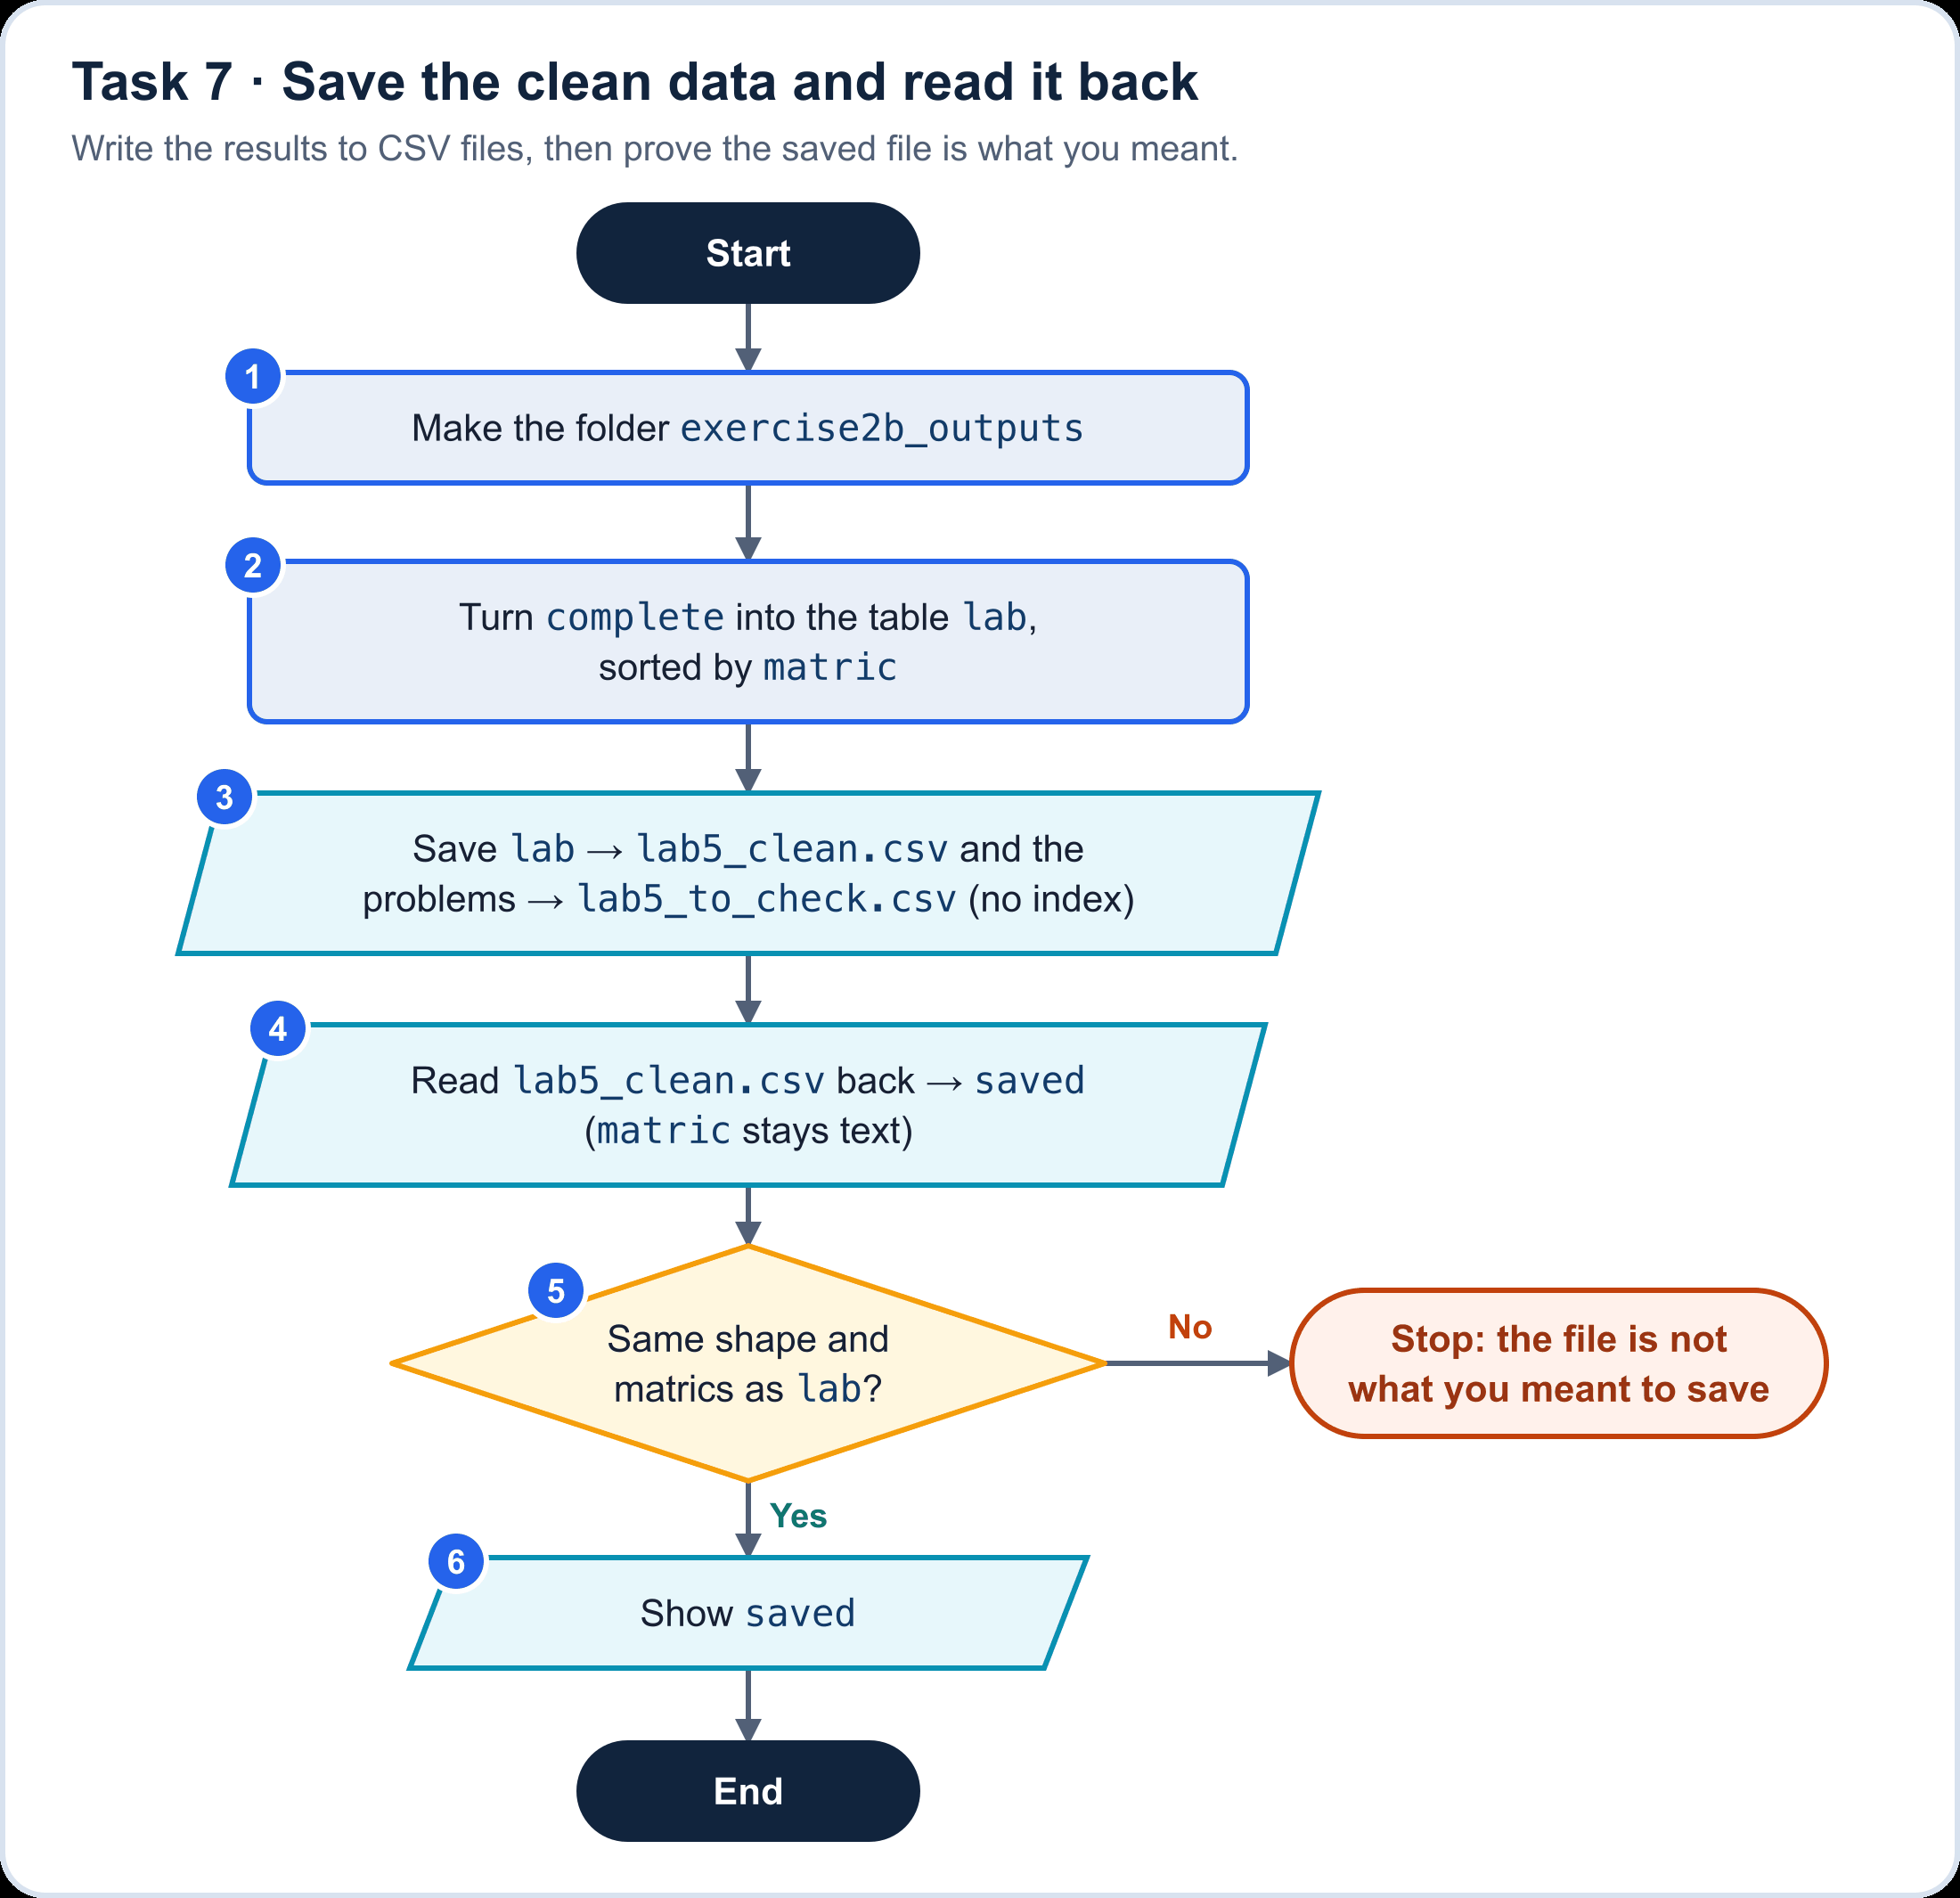

In [ ]:
# ① exist_ok=True: no error if the folder is already there
OUT_DIR = Path("exercise2b_outputs")
OUT_DIR.____(exist_ok=True)

# ② A list of dictionaries becomes a table: one dictionary per row
lab = pd.____(complete).sort_values("matric")
to_check = pd.DataFrame(still_to_check)

# ③ Leave out the row labels
lab.to_csv(OUT_DIR / "lab5_clean.csv", index=____, encoding="utf-8")
to_check.to_csv(OUT_DIR / "lab5_to_check.csv", index=False, encoding="utf-8")

# ④ Read the file you actually saved. A matric is a label, so keep it as text
saved = pd.____(OUT_DIR / "lab5_clean.csv", dtype={"matric": "string"})

# ⑤ One question about the whole file, so an ordinary if
if saved.shape != lab.shape ____ saved["matric"].tolist() != lab["matric"].tolist():
    raise ValueError("The saved file is not the table you meant to save")

# ⑥
print(saved)

In [ ]:
# Check: run this after the cell above
header = (OUT_DIR / "lab5_clean.csv").read_text(encoding="utf-8").splitlines()[0]
assert header == "matric,name,lab", "③ the first line should be the header only: leave out the index"
assert saved["matric"].tolist() == ["S101", "S102", "S103", "S104", "S105", "S106"], "② sort by matric"
assert saved["lab"].tolist() == [24, 20, 28, 22, 16, 14], "④ read the clean file back"
assert len(pd.read_csv(OUT_DIR / "lab5_to_check.csv")) == 5, "③ save the 5 lines still to check"
print("✅ Task 7 done")

**✍️ Think:** What would the first line of `lab5_clean.csv` be without `index=False`, and what would step ⑤ do?

*Your answer:* 

---
## Task 8 · Challenge: write all the code yourself

**Question:** Write a plain-text report with one aligned line per student and a footer saying what is left to check.

![Task 8 flowchart: Start; 1 report_lines holds the title line; inside a frame for each row of saved, 2 pct is lab divided by 30 times 100; 3 is pct at least 50? Yes result is PASS, No result is FAIL; 4 format one aligned line and add it to report_lines; after the frame, 5 add a footer with how many were accepted and the line numbers to check; 6 join the lines with newlines and write them to lab5_report.txt; 7 read the report back and show it; End.](attachment:task8.png)

There are no blanks this time: write the code for every step. Keep the name `REPORT_FILE` for the file and `report_text` for the text you read back.

**Hints**

- ① Start a list that holds the title line `"Lab 5 marks (out of 30)"`. You will `.append()` one line per student.
- ② `for student in saved.to_dict("records"):` gives one dictionary per row, like the ones in Task 5.
- ③ One student's percentage is a single value, so an ordinary `if` / `else` works.
- ④ `f"{student['matric']}  {student['name']:<8}{student['lab']:>3}  {pct:5.1f}%  {result}"`
- ⑤ `", ".join(...)` needs strings: turn each line number into text with `str()`.
- ⑥ ⑦ You wrote and read a file in Task 1.

**Expected result**

```text
Lab 5 marks (out of 30)
S101  Aina     24   80.0%  PASS
S102  Ben      20   66.7%  PASS
S103  Chong    28   93.3%  PASS
S104  Devi     22   73.3%  PASS
S105  Emir     16   53.3%  PASS
S106  Farah    14   46.7%  FAIL
6 students accepted. Lines to check in lab5_raw.txt: 9, 10, 11, 12, 13
```
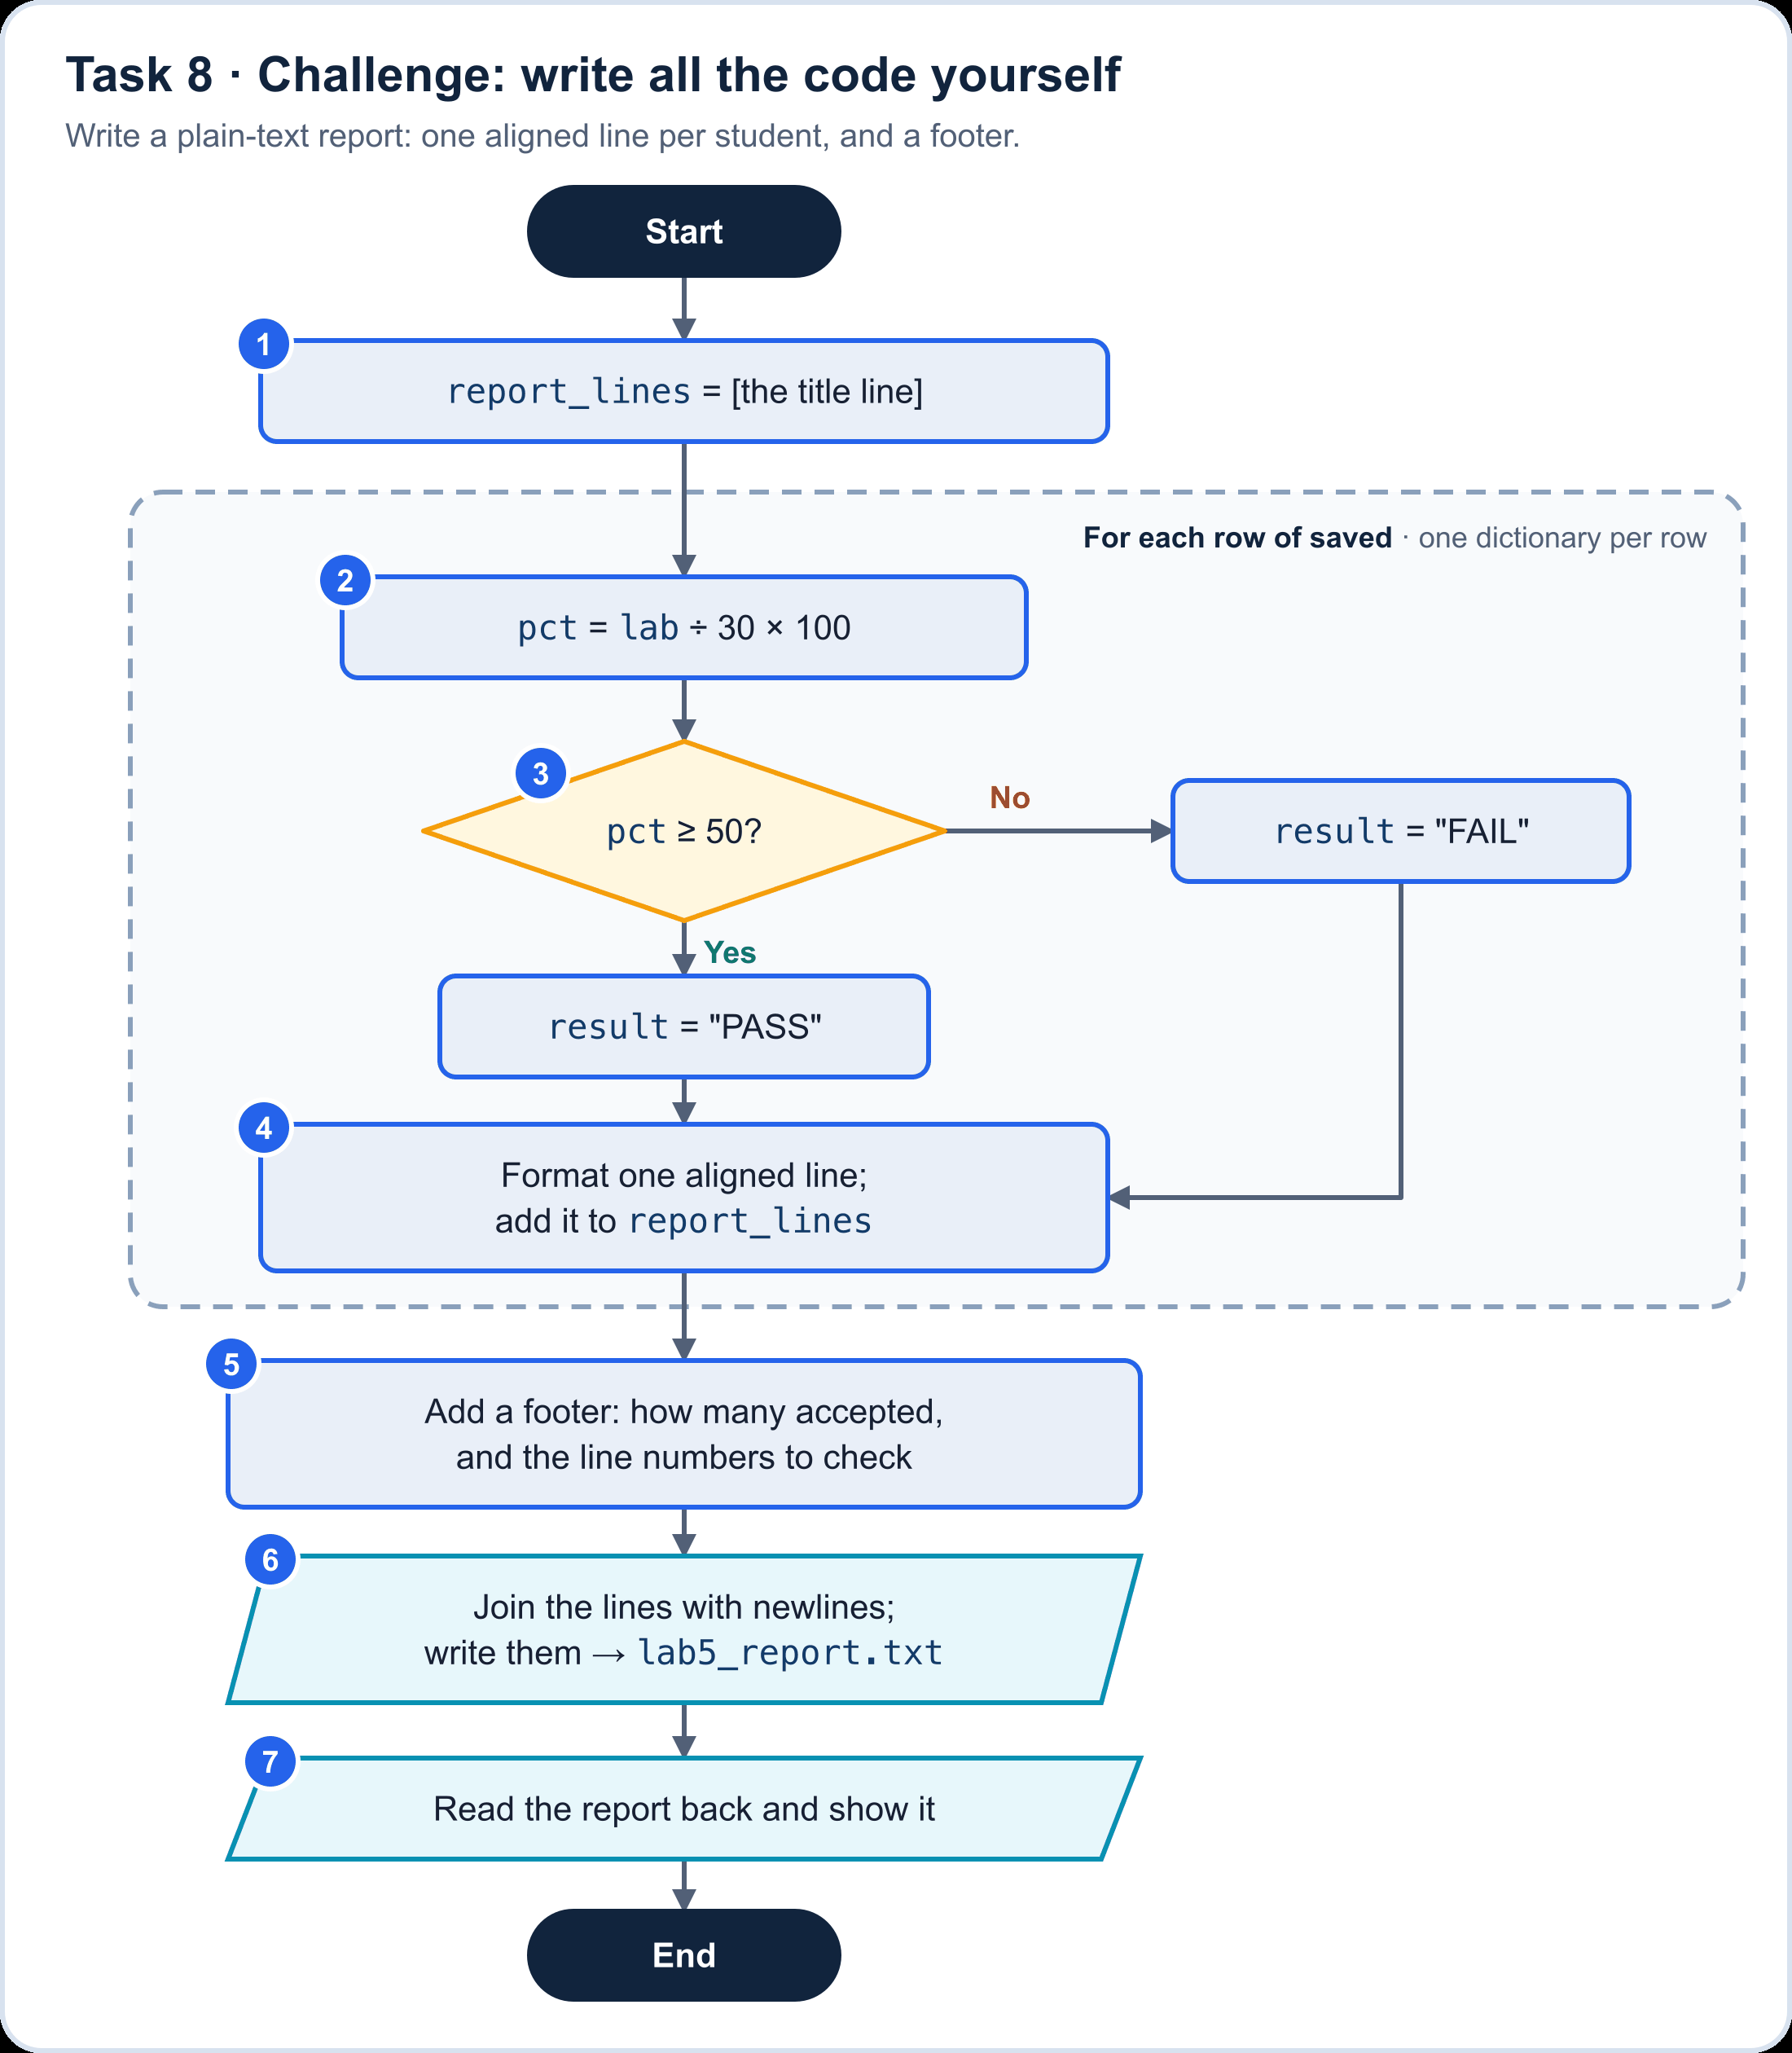

In [ ]:
# ①


# ② ③ ④


# ⑤


# ⑥
REPORT_FILE = OUT_DIR / "lab5_report.txt"


# ⑦

print(report_text)

In [ ]:
# Check: run this after the cell above
report = report_text.splitlines()
assert REPORT_FILE.exists(), "⑥ write the report to REPORT_FILE"
assert len(report) == 8, "expected a title line, 6 student lines and a footer, one per line"
assert report[1].split() == ["S101", "Aina", "24", "80.0%", "PASS"], "④ expected: S101  Aina  24  80.0%  PASS"
assert report[6].split() == ["S106", "Farah", "14", "46.7%", "FAIL"], "③ Farah is below 50%"
assert report[-1].startswith("6 students accepted") and report[-1].endswith("9, 10, 11, 12, 13"), "⑤ footer: the count, then the line numbers to check"
print("✅ Task 8 done: great work!")

**✍️ Think:** The report lists 6 students, but the tutor typed 11 lines of marks. Why does the footer matter as much as the student lines?

*Your answer:* 

---
## Wrap-up: what did each symbol become?

Fill in the middle column with the Python you wrote today.

| Flowchart symbol | Became in Python | Tasks |
|---|---|---|
| Parallelogram that reads or writes a file |  | 1, 5, 7, 8 |
| Chain of diamonds inside a function |  | 4 |
| Diamond: *does the whole code match?* |  | 3, 5 |
| *For each* frame |  | 3, 5, 8 |
| Branch that skips to the next item |  | 5 |
| Arrow that loops back up to a diamond |  | 6 |

**Before you finish:** choose **Kernel → Restart Kernel and Run All Cells**. Every Check cell should print ✅.